# 17 — Supervised demand model: Random Forest regressor

Third candidate for the supervised stage, after the seasonal-naive/group-mean
baselines and the single Decision Tree of
[`15_decision_tree.ipynb`](15_decision_tree.ipynb).
It consumes the same training matrix persisted by notebook 13
(`data/processed/north_region_mama_2025_modeling_matrix_atuantes_v1.parquet`)
and produces the Random Forest row of **documentation Section 4.3.9**.

**What is deliberately reused, not re-derived.** The target, the eight approved
predictors, the temporal split and the metric definitions all come from
notebook 15 verbatim, so the three candidates are compared on identical data.
Notebook 15 is not modified by this notebook.

**Target.** `volume_demanda_proxy` = sum of `QT_ITEM_EVENTO_INFORMADO` per
`ID_PLANO × treatment_line_primary × UF_PRESTADOR × MES`, fixed upstream in
`documents/extras/target_definition_potencial_pacientes.md`. It is a billed
utilization-volume proxy, **not** a patient count.

**What this notebook adds over notebook 15's Random Forest row.** Notebook 15
fits a single 300-tree forest as a variance-reduction check. Here the forest is
tuned across four configurations spanning the capacity range, each one timed,
and its feature importances are put side by side with the Decision Tree's to
test whether both models agree on which predictors matter.

**Reading order.** Sections 1–11 run on notebook 13's **as-of** matrix, in which every
row is one a forecaster could have been asked for at the start of its month, so every
split used here — the holdout and each validation fold — is free of look-ahead. Section
12 verifies that property on the file itself and measures what fixing notebook 13
changed, against a rebuild of the old full-year matrix. Section 13 measures what the
unvalidated `treatment_line_primary` rule does and does not affect, including one result
that changes how the model should be used. The saved model and prediction base (section
14) come from the section 6 forest. Section 17 explains that saved forest with SHAP.

## 0. Configuration

Every constant that notebook 15 fixed is repeated here with the same value and
the same name. `RANDOM_STATE` is set on every estimator instantiation, not once
globally, because a forest draws bootstrap samples and feature subsets per fit.

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- identical to notebook 15, section 0 -------------------------------------
RANDOM_STATE = 42
HOLDOUT_MONTHS = 3          # last 3 calendar months are the untouched test set
N_CV_FOLDS = 3              # expanding-window validation folds, before the holdout

UNIT_KEYS = ["ID_PLANO", "treatment_line_primary", "UF_PRESTADOR", "MES"]
GROUP_KEYS_NO_MONTH = ["ID_PLANO", "treatment_line_primary", "UF_PRESTADOR"]
TARGET = "volume_demanda_proxy"
APPROVED_X = [
    "DEMAND_LAG_1M", "DEMAND_LAG_3M", "DEMAND_LAG_6M",
    "DEMAND_MEAN_3M", "DEMAND_MEAN_6M", "DEMAND_STD_3M",
    "PORTE_ORDINAL", "MONTH",
]
# -----------------------------------------------------------------------------

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

WORKING_DIR = Path.cwd().resolve()
REPO_ROOT = WORKING_DIR.parent if WORKING_DIR.name == "notebooks" else WORKING_DIR
PROC = REPO_ROOT / "data" / "processed"
ASSETS = REPO_ROOT / "assets"
ASSETS.mkdir(parents=True, exist_ok=True)

MATRIX_PATH = PROC / "north_region_mama_2025_modeling_matrix_atuantes_v1.parquet"
TREATED_PATH = PROC / "north_region_mama_2025_data_en_medicina_de_grupo.parquet"
if not TREATED_PATH.is_file():
    raise FileNotFoundError(
        "Missing Medicina de Grupo base. Run data_pipeline/08_filter_medicina_de_grupo.ipynb "
        f"first. Expected path: {TREATED_PATH}"
    )

print("matrix:", MATRIX_PATH)
print("exists:", MATRIX_PATH.is_file())

matrix: /Users/lucasdaddazio/projetos/Inteli/1-ano/g02/data/processed/north_region_mama_2025_modeling_matrix_atuantes_v1.parquet
exists: True


## 1. Load the modeling matrix and re-assert its contract

The asserts are not decoration: if notebook 13's output ever changes shape, this
notebook must fail loudly rather than silently train on a different feature set
than notebook 15 did.

`sklearn >= 1.4` splits on `NaN` natively for both `DecisionTreeRegressor` and
`RandomForestRegressor`, so the lag burn-in `NaN`s (the first months of each
unit's observed span, `NaN` by construction of `groupby.shift`) are kept rather
than imputed. Imputing them would invent history that does not exist.

In [2]:
matrix = pd.read_parquet(MATRIX_PATH)
matrix["MES"] = pd.to_datetime(matrix["MES"])

assert matrix[UNIT_KEYS].duplicated().sum() == 0, "duplicate modeling keys"
assert matrix[TARGET].notna().all(), "persisted training matrix must have no null target"
missing_x = [c for c in APPROVED_X if c not in matrix.columns]
assert not missing_x, f"approved predictors absent from the matrix: {missing_x}"

print("matrix shape:", matrix.shape)
print("months:", matrix['MES'].min().date(), "..", matrix['MES'].max().date(),
      f"({matrix['MES'].nunique()} months)")
print("distinct operators:", matrix["ID_PLANO"].nunique())
print("\nlag burn-in NaNs per predictor:")
print(matrix[APPROVED_X].isna().sum().to_string())

matrix shape: (11526, 13)
months: 2025-02-01 .. 2025-12-01 (11 months)
distinct operators: 507

lag burn-in NaNs per predictor:
DEMAND_LAG_1M       87
DEMAND_LAG_3M     1451
DEMAND_LAG_6M     4438
DEMAND_MEAN_3M     206
DEMAND_MEAN_6M     305
DEMAND_STD_3M      765
PORTE_ORDINAL        0
MONTH                0


### 1.1 Structural-zero mask

Notebook 13 reindexes each `(operator × line × UF)` group over every month from
its operator's first claim to the end of the data, and assigns zero to the
months with no claim. Those **structural zeros** are predicted trivially by
any model and inflate R² — so, like notebook 15, every metric is reported twice:
over all holdout rows, and over observed rows only.

Notebook 15 reads this flag from a diagnostics companion parquet. That companion
is written by the version of notebook 13 on the `feat/decision-tree-model`
branch and does **not** exist here, so the mask is rebuilt from the treated base
instead: a key that appears in `df_norte` was observed, a key that does not was
manufactured by the reindex. This reads the base read-only and changes nothing
upstream.

In [3]:
HAS_DIAG = TREATED_PATH.is_file()
if HAS_DIAG:
    # Rebuild treatment_line_primary with notebook 13's placeholder priority rule
    # (advanced > adjuvant > neoadjuvant > staging). Unvalidated -- see section 8.
    cols = ["ID_PLANO", "UF_PRESTADOR", "MES", "IND_LINE_STAGING",
            "IND_LINE_NEOADJUVANT", "IND_LINE_ADJUVANT", "IND_LINE_ADVANCED"]
    df_norte = pd.read_parquet(TREATED_PATH, columns=cols)
    df_norte["MES"] = pd.to_datetime(df_norte["MES"])
    df_norte["treatment_line_primary"] = np.select(
        [df_norte["IND_LINE_ADVANCED"] == 1, df_norte["IND_LINE_ADJUVANT"] == 1,
         df_norte["IND_LINE_NEOADJUVANT"] == 1, df_norte["IND_LINE_STAGING"] == 1],
        ["advanced", "adjuvant", "neoadjuvant", "staging"], default="unclassified")

    observed_keys = set(map(tuple, df_norte[UNIT_KEYS].drop_duplicates().to_numpy()))
    matrix["IS_STRUCTURAL_ZERO"] = ~pd.Series(
        [tuple(r) in observed_keys for r in matrix[UNIT_KEYS].to_numpy()],
        index=matrix.index)
    del df_norte
    print("structural zeros:", int(matrix['IS_STRUCTURAL_ZERO'].sum()),
          f"({matrix['IS_STRUCTURAL_ZERO'].mean()*100:.1f}% of rows)")
    print("observed rows   :", int((~matrix['IS_STRUCTURAL_ZERO']).sum()))
else:
    matrix["IS_STRUCTURAL_ZERO"] = False
    print("treated base absent -- observed-only metrics will not be reported")

structural zeros: 5277 (45.8% of rows)
observed rows   : 6249


## 2. Temporal split — reused, not re-created

Identical to notebook 15, section 2: split on `MES`, never a random `KFold`.

A random fold would place month `t+1` of a unit in train and month `t` in test,
and `DEMAND_LAG_1M` would then carry the test target verbatim. `GroupKFold` by
`ID_PLANO` avoids that specific leak but still mixes calendar periods across
folds, which corresponds to no real forecast scenario. See
`scripts/diagnose_modeling_matrix.py`, section 12.

* **Test (holdout)** — the last `HOLDOUT_MONTHS` months, untouched until section 6.
* **Validation** — `N_CV_FOLDS` expanding-window folds over the months
  immediately before the holdout; each fold trains on everything strictly
  earlier. Configuration selection uses these folds only.

There is no `train_test_split` and therefore no split proportion or split seed:
the partition is a deterministic function of the calendar, so it is reproducible
by construction and identical to notebook 15's by definition.

In [4]:
months = np.sort(matrix["MES"].unique())
assert len(months) > HOLDOUT_MONTHS + N_CV_FOLDS, "not enough months for the split"

cutoff = pd.Timestamp(months[-HOLDOUT_MONTHS])
train = matrix[matrix["MES"] < cutoff].copy()
holdout = matrix[matrix["MES"] >= cutoff].copy()
assert set(train["MES"]).isdisjoint(set(holdout["MES"])), "train and holdout share a month"

cv_months = [pd.Timestamp(m) for m in months[-(HOLDOUT_MONTHS + N_CV_FOLDS):-HOLDOUT_MONTHS]]
folds = [(matrix[matrix["MES"] < m], matrix[matrix["MES"] == m]) for m in cv_months]

print(f"cutoff (first holdout month): {cutoff.date()}")
print(f"train: {len(train):,} rows  |  holdout: {len(holdout):,} rows")
print("CV folds (train_rows / valid_rows):")
for m, (tr, va) in zip(cv_months, folds):
    print(f"  fold {m.date()}: {len(tr):,} / {len(va):,}")

cutoff (first holdout month): 2025-10-01
train: 7,716 rows  |  holdout: 3,810 rows
CV folds (train_rows / valid_rows):
  fold 2025-07-01: 4,238 / 1,086
  fold 2025-08-01: 5,324 / 1,154
  fold 2025-09-01: 6,478 / 1,238


## 3. Metrics — same functions, same precision as notebook 15

`evaluate()` is copied from notebook 15 section 3 unchanged, so the numbers are
directly comparable. Predictions are clipped at zero because demand cannot be
negative. Metrics are computed at full float precision and rounded only for
display, exactly as notebook 15 does.

The project's **primary metric is MAE**: the target is zero-inflated and heavily
right-skewed, so RMSE and R² are dominated by a handful of large operator-months.
The task for this notebook asks for R², MAE and RMSE; all three are reported,
with MAE carrying the selection decision to stay aligned with Section 4.3.9.2.

In [5]:
def evaluate(y_true, y_pred, mask=None, baseline_mae=None) -> dict:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 0, None)  # demand can't be negative
    if mask is not None:
        y_true, y_pred = y_true[mask], y_pred[mask]
    mae = mean_absolute_error(y_true, y_pred)
    out = {
        "n": int(len(y_true)),
        "MAE": mae,
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
        "MAE_log1p": mean_absolute_error(np.log1p(np.clip(y_true, 0, None)), np.log1p(y_pred)),
    }
    if baseline_mae is not None:
        out["skill_vs_naive"] = 1 - mae / baseline_mae
    return out


y_hold = holdout[TARGET].to_numpy(dtype=float)
obs_mask = (~holdout["IS_STRUCTURAL_ZERO"].to_numpy()) if HAS_DIAG else None

# Baseline: seasonal naive -- predict the last observed month (DEMAND_LAG_1M),
# 0 where the unit has no history yet. This is notebook 15's reference for the
# skill score, recomputed here so this notebook stands alone.
pred_naive = np.nan_to_num(holdout["DEMAND_LAG_1M"].to_numpy(dtype=float), nan=0.0)
naive_mae_all = mean_absolute_error(y_hold, np.clip(pred_naive, 0, None))
baseline_all = evaluate(y_hold, pred_naive, baseline_mae=naive_mae_all)

print("seasonal-naive baseline, all holdout rows:")
print({k: round(v, 4) for k, v in baseline_all.items()})

seasonal-naive baseline, all holdout rows:
{'n': 3810, 'MAE': 19.7236, 'RMSE': 74.895, 'R2': 0.6112, 'MAE_log1p': 0.522, 'skill_vs_naive': 0.0}


## 4. Random Forest — Hyperparameter Tuning

To optimize the Random Forest regressor, four hyperparameter configurations
were evaluated using the same expanding-window validation folds defined above.
The search varies `n_estimators`, `max_depth`, and `min_samples_leaf`, which
control the size of the ensemble and the complexity of the individual trees.

The configurations were selected to cover different levels of model complexity,
from highly constrained forests to deeper and less regularized alternatives.

The best configuration is selected exclusively according to the lowest mean
validation MAE. The holdout set is not used for hyperparameter selection.

Why these values and not others:

| Config | `n_estimators` | `max_depth` | `min_samples_leaf` | What it tests |
|---|---|---|---|---|
| `rf_small_shallow` | 150 | 6 | 100 | Heavily constrained. Depth 6 and 100-row leaves match the *upper* end of notebook 15's Decision Tree grid, so this isolates the effect of bagging alone at a capacity the single tree already explored. |
| `rf_mid` | 300 | 12 | 20 | Notebook 15's tree count with moderate depth. This is the closest analogue to the forest already reported there, and the reference point for the comparison table. |
| `rf_deep_large` | 600 | `None` | 5 | Fully grown trees, doubled ensemble. Tests whether the variance reduction from more trees is enough to make unrestricted depth safe on 8 features. |
| `rf_deep_regularized` | 600 | 20 | 50 | Same ensemble size as above but regularized, to separate "more trees helped" from "deeper trees helped". |

`min_samples_leaf` never goes below 5: the target is zero-inflated, and leaves
of one or two rows would memorize individual operator-months. `max_features` is
left at the sklearn default (1.0 for regression), because with only 8 predictors
subsampling features per split would discard a large fraction of the signal at
every node.

In [6]:
RF_CONFIGS = {
    "rf_small_shallow":    dict(n_estimators=150, max_depth=6,    min_samples_leaf=100),
    "rf_mid":              dict(n_estimators=300, max_depth=12,   min_samples_leaf=20),
    "rf_deep_large":       dict(n_estimators=600, max_depth=None, min_samples_leaf=5),
    "rf_deep_regularized": dict(n_estimators=600, max_depth=20,   min_samples_leaf=50),
}


def make_rf(**params) -> RandomForestRegressor:
    # random_state is fixed on every instantiation: bootstrap draws are per-fit.
    return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **params)


for name, params in RF_CONFIGS.items():
    print(f"{name:22s} {params}")

rf_small_shallow       {'n_estimators': 150, 'max_depth': 6, 'min_samples_leaf': 100}
rf_mid                 {'n_estimators': 300, 'max_depth': 12, 'min_samples_leaf': 20}
rf_deep_large          {'n_estimators': 600, 'max_depth': None, 'min_samples_leaf': 5}
rf_deep_regularized    {'n_estimators': 600, 'max_depth': 20, 'min_samples_leaf': 50}


### 4.1 Validation pass — selection happens here, on the folds, never on the test set

Each configuration is scored by mean MAE across the expanding-window folds. The
holdout is not touched in this cell. Wall-clock fit time is accumulated with
`time.perf_counter()` around the `.fit()` calls only, excluding prediction and
scoring, so the number is comparable across configurations.

In [7]:
cv_rows = []
for name, params in RF_CONFIGS.items():
    fold_maes, fit_seconds = [], 0.0
    for tr, va in folds:
        est = make_rf(**params)
        t0 = time.perf_counter()
        est.fit(tr[APPROVED_X], tr[TARGET])
        fit_seconds += time.perf_counter() - t0
        fold_maes.append(mean_absolute_error(va[TARGET], np.clip(est.predict(va[APPROVED_X]), 0, None)))
    cv_rows.append({
        "config": name, **params,
        "cv_MAE": float(np.mean(fold_maes)),
        "cv_MAE_std": float(np.std(fold_maes)),
        "cv_fit_seconds_total": fit_seconds,
        "cv_fit_seconds_per_fit": fit_seconds / len(folds),
    })

cv_results = pd.DataFrame(cv_rows).sort_values("cv_MAE").reset_index(drop=True)
BEST_CONFIG_NAME = cv_results.loc[0, "config"]
BEST_PARAMS = RF_CONFIGS[BEST_CONFIG_NAME]
print("selected on validation MAE:", BEST_CONFIG_NAME, BEST_PARAMS)
cv_results.round(4)

selected on validation MAE: rf_deep_large {'n_estimators': 600, 'max_depth': None, 'min_samples_leaf': 5}


,config,n_estimators,max_depth,min_samples_leaf,cv_MAE,cv_MAE_std,cv_fit_seconds_total,cv_fit_seconds_per_fit
0,rf_deep_large,600,NaN,5,31.0112,2.4334,1.4270,0.4757
1,rf_mid,300,12.0,20,31.2584,3.2576,0.6025,0.2008
2,rf_deep_regularized,600,20.0,50,32.9363,2.7201,1.1338,0.3779
3,rf_small_shallow,150,6.0,100,33.8856,3.3468,0.2843,0.0948


In [8]:
tuning_summary = cv_results[
    [
        "config",
        "n_estimators",
        "max_depth",
        "min_samples_leaf",
        "cv_MAE",
        "cv_MAE_std",
    ]
].copy()

tuning_summary

,config,n_estimators,max_depth,min_samples_leaf,cv_MAE,cv_MAE_std
0,rf_deep_large,600,NaN,5,31.011184,2.433362
1,rf_mid,300,12.0,20,31.258393,3.257644
2,rf_deep_regularized,600,20.0,50,32.936333,2.720058
3,rf_small_shallow,150,6.0,100,33.885619,3.346815


In [9]:
print("Selected configuration:", BEST_CONFIG_NAME)
print("Best parameters:", BEST_PARAMS)
print(f"Validation MAE: {cv_results.loc[0, 'cv_MAE']:.4f}")

Selected configuration: rf_deep_large
Best parameters: {'n_estimators': 600, 'max_depth': None, 'min_samples_leaf': 5}
Validation MAE: 31.0112


## 5. Decision Tree reference

To compare against the Decision Tree fairly, the tree is re-fitted **here** using
notebook 15's exact search grid and the exact same folds. Notebook 15's file is
not imported or modified; its procedure is reproduced so that both models in the
importance comparison below were selected the same way on the same data.

In [10]:
def cv_mae_tree(factory) -> float:
    scores = []
    for tr, va in folds:
        est = factory()
        est.fit(tr[APPROVED_X], tr[TARGET])
        scores.append(mean_absolute_error(va[TARGET], np.clip(est.predict(va[APPROVED_X]), 0, None)))
    return float(np.mean(scores))


# notebook 15, section 4 -- same grid, same order
tree_search = []
for max_depth in [3, 4, 5, 6, 8, 10, None]:
    for min_samples_leaf in [20, 50, 100, 200]:
        for ccp_alpha in [0.0, 1e-3, 1e-2]:
            mae = cv_mae_tree(lambda d=max_depth, l=min_samples_leaf, a=ccp_alpha:
                              DecisionTreeRegressor(max_depth=d, min_samples_leaf=l,
                                                    ccp_alpha=a, random_state=RANDOM_STATE))
            tree_search.append({"max_depth": max_depth, "min_samples_leaf": min_samples_leaf,
                                "ccp_alpha": ccp_alpha, "cv_MAE": mae})

tree_search = pd.DataFrame(tree_search).sort_values("cv_MAE").reset_index(drop=True)
best_tree = tree_search.iloc[0].to_dict()
print("best Decision Tree config (validation MAE):", {k: best_tree[k] for k in
      ("max_depth", "min_samples_leaf", "ccp_alpha", "cv_MAE")})
tree_search.head()

best Decision Tree config (validation MAE): {'max_depth': 6.0, 'min_samples_leaf': 20.0, 'ccp_alpha': 0.01, 'cv_MAE': 31.33272744607466}


,max_depth,min_samples_leaf,ccp_alpha,cv_MAE
0,6.0,20,0.010,31.332727
1,6.0,20,0.001,31.332727
2,6.0,20,0.000,31.332727
3,10.0,20,0.000,31.855712
4,10.0,20,0.001,31.864573


## 6. Final fits and holdout metrics

Only now is the holdout used. Every configuration is refitted on the full
training partition and scored once on the test set, so the table shows what each
configuration *would* have scored — but the row that goes into Section 4.3.9 is
the one selected on validation in section 4.1, not the best test row.

The holdout results for all configurations are reported for diagnostic purposes
only. The model selected for the final comparison is the configuration chosen
using validation MAE, independently of holdout performance.

Training time is measured again here on the full training partition, which is
the number that matters for retraining cost.


In [11]:
def timed_fit(est, X, y):
    t0 = time.perf_counter()
    est.fit(X, y)
    return est, time.perf_counter() - t0


fitted, rows = {}, []

tree_final = DecisionTreeRegressor(
    max_depth=None if pd.isna(best_tree["max_depth"]) else int(best_tree["max_depth"]),
    min_samples_leaf=int(best_tree["min_samples_leaf"]),
    ccp_alpha=float(best_tree["ccp_alpha"]), random_state=RANDOM_STATE)
tree_final, tree_seconds = timed_fit(tree_final, train[APPROVED_X], train[TARGET])
fitted["decision_tree"] = tree_final

for name, params in RF_CONFIGS.items():
    est, secs = timed_fit(make_rf(**params), train[APPROVED_X], train[TARGET])
    fitted[name] = est
    m_all = evaluate(y_hold, est.predict(holdout[APPROVED_X]), baseline_mae=naive_mae_all)
    row = {"model": name, **params, "fit_seconds": secs,
           "R2": m_all["R2"], "MAE": m_all["MAE"], "RMSE": m_all["RMSE"],
           "MAE_log1p": m_all["MAE_log1p"], "skill_vs_naive": m_all["skill_vs_naive"]}
    if obs_mask is not None:
        m_obs = evaluate(y_hold, est.predict(holdout[APPROVED_X]), mask=obs_mask)
        row |= {"R2_obs": m_obs["R2"], "MAE_obs": m_obs["MAE"], "RMSE_obs": m_obs["RMSE"],
                "MAE_log1p_obs": m_obs["MAE_log1p"]}
    rows.append(row)

holdout_results = pd.DataFrame(rows)
print(f"Decision Tree fit time on the same training partition: {tree_seconds:.3f} s")
holdout_results.round(4)

Decision Tree fit time on the same training partition: 0.007 s


,model,n_estimators,max_depth,min_samples_leaf,fit_seconds,R2,MAE,RMSE,MAE_log1p,skill_vs_naive,R2_obs,MAE_obs,RMSE_obs,MAE_log1p_obs
0,rf_small_shallow,150,6.0,100,0.1072,0.5779,19.7836,78.0362,0.6989,-0.0030,0.6103,34.5039,107.8963,0.4430
1,rf_mid,300,12.0,20,0.2804,0.5981,17.6073,76.1496,0.5896,0.1073,0.7212,30.0853,91.2676,0.4561
2,rf_deep_large,600,NaN,5,0.6860,0.4209,18.1414,91.4047,0.5828,0.0802,0.7182,30.1551,91.7575,0.4712
3,rf_deep_regularized,600,20.0,50,0.5061,0.6590,17.3430,70.1367,0.6019,0.1207,0.7141,29.7934,92.4199,0.4464


In [12]:
best_rf = make_rf(**BEST_PARAMS)
best_rf, best_rf_seconds = timed_fit(
    best_rf,
    train[APPROVED_X],
    train[TARGET]
)

best_pred = best_rf.predict(holdout[APPROVED_X])

best_metrics = evaluate(
    y_hold,
    best_pred,
    baseline_mae=naive_mae_all
)

best_metrics

{'n': 3810,
 'MAE': 18.141430644998184,
 'RMSE': 91.40465057140425,
 'R2': 0.4209123341173414,
 'MAE_log1p': 0.5828081482884441,
 'skill_vs_naive': 0.08021809576639016}

### 6.1 The three candidates side by side

Baselines and the Decision Tree are scored with the identical `evaluate()` call
so that Section 4.3.10.3's table can be filled straight from this frame.

In [13]:
def row_for(label, pred, seconds=np.nan, hyper=""):
    m = evaluate(y_hold, pred, baseline_mae=naive_mae_all)
    out = {"Model": label, "Hyperparameters": hyper, "fit_seconds": seconds,
           "MAE": m["MAE"], "RMSE": m["RMSE"], "R2": m["R2"],
           "MAE_log1p": m["MAE_log1p"], "skill_vs_naive": m["skill_vs_naive"]}
    if obs_mask is not None:
        mo = evaluate(y_hold, pred, mask=obs_mask)
        out |= {"MAE_obs": mo["MAE"], "RMSE_obs": mo["RMSE"], "R2_obs": mo["R2"],
                "MAE_log1p_obs": mo["MAE_log1p"]}
    return out


# Group-mean baseline: training mean per operator x line x UF, global mean as fallback.
grp_mean = train.groupby(GROUP_KEYS_NO_MONTH, observed=True)[TARGET].mean()
pred_grpmean = (holdout.set_index(GROUP_KEYS_NO_MONTH).index.map(grp_mean)
                .to_numpy(dtype=float))
pred_grpmean = np.nan_to_num(pred_grpmean, nan=float(train[TARGET].mean()))

# max_depth arrives as float because the grid mixes ints with None; print it as
# it was specified so the documentation table quotes the real hyperparameter.
_td = best_tree["max_depth"]
tree_hyper = (f"max_depth={'None' if pd.isna(_td) else int(_td)}, "
              f"min_samples_leaf={int(best_tree['min_samples_leaf'])}, "
              f"ccp_alpha={best_tree['ccp_alpha']}")
rf_hyper = ", ".join(f"{k}={v}" for k, v in BEST_PARAMS.items())

comparison = pd.DataFrame([
    row_for("Seasonal-naive baseline", pred_naive, hyper="none"),
    row_for("Group-mean baseline", pred_grpmean, hyper="none"),
    row_for("Decision Tree", tree_final.predict(holdout[APPROVED_X]), tree_seconds, tree_hyper),
    row_for(f"Random Forest ({BEST_CONFIG_NAME})",
            fitted[BEST_CONFIG_NAME].predict(holdout[APPROVED_X]),
            float(holdout_results.loc[holdout_results['model'] == BEST_CONFIG_NAME, 'fit_seconds'].iloc[0]),
            rf_hyper),
])
comparison.round(4)

,Model,Hyperparameters,fit_seconds,MAE,RMSE,R2,MAE_log1p,skill_vs_naive,MAE_obs,RMSE_obs,R2_obs,MAE_log1p_obs
0,Seasonal-naive baseline,none,NaN,19.7236,74.8950,0.6112,0.5220,0.0000,38.2162,108.6791,0.6046,0.7006
1,Group-mean baseline,none,NaN,31.1255,128.7657,-0.1492,0.8594,-0.5781,44.4547,124.5143,0.4810,0.5677
2,Decision Tree,"max_depth=6, min_samples_leaf=20, ccp_alpha=0.01",0.0067,19.0651,89.5904,0.4437,0.7261,0.0334,31.8064,97.1970,0.6838,0.4649
3,Random Forest (rf_deep_large),"n_estimators=600, max_depth=None, min_samples_...",0.6860,18.1414,91.4047,0.4209,0.5828,0.0802,30.1551,91.7575,0.7182,0.4712


The `skill_vs_naive` column above is computed against the all-rows naive MAE. The
observed-only column needs its own reference, because the naive baseline's own MAE
changes once the structural zeros are removed — comparing an observed-row model
MAE against an all-row baseline MAE would flatter every model. This cell
recomputes it on the correct denominator.

In [14]:
if obs_mask is not None:
    naive_mae_obs = mean_absolute_error(y_hold[obs_mask], np.clip(pred_naive, 0, None)[obs_mask])
    skill_obs = comparison.assign(
        skill_vs_naive_obs=1 - comparison["MAE_obs"] / naive_mae_obs
    )[["Model", "MAE", "skill_vs_naive", "MAE_obs", "skill_vs_naive_obs"]]
    print(f"naive MAE on observed rows only: {naive_mae_obs:.4f}"
          f"  (all rows: {naive_mae_all:.4f})")
    display(skill_obs.round(4))
else:
    print("no structural-zero mask -- observed-only skill not available")

naive MAE on observed rows only: 38.2162  (all rows: 19.7236)


,Model,MAE,skill_vs_naive,MAE_obs,skill_vs_naive_obs
0,Seasonal-naive baseline,19.7236,0.0000,38.2162,0.0000
1,Group-mean baseline,31.1255,-0.5781,44.4547,-0.1632
2,Decision Tree,19.0651,0.0334,31.8064,0.1677
3,Random Forest (rf_deep_large),18.1414,0.0802,30.1551,0.2109


### 6.1.1 The result that has to be reported first

**On all holdout rows, every fitted model now beats the seasonal-naive baseline on
MAE.** The baseline's skill score is 0.000 by construction; Random Forest scores
**+0.080**, Decision Tree **+0.033**, and only the group-mean baseline is negative at
−0.578. This is a reversal of the full-population run, where the naive forecast won the
all-rows comparison outright, and it is the first time in this project that the primary
metric of Section 4.3.9.2 points at a fitted model rather than at "predict last month's
volume".

The all-rows column still flatters every model, and the reason is the zero rows. 56.1% of
the holdout is months in which a known combination billed nothing; on those rows
`DEMAND_LAG_1M` is usually 0 and the truth is 0, so the naive forecast is exactly right for
free on more than half the data, and any model that lands near zero there scores well
without having forecast anything.

Excluding them widens the gap rather than closing it: **on observed rows only, the Random
Forest leads by a clear margin**, MAE 30.16 against 38.22, a skill of **+0.211**, with the
better R² (0.718 vs 0.605) and RMSE (91.8 vs 108.7). The Decision Tree manages it too,
at 31.81 and +0.168, so both tree models beat the baseline on both row sets.

So the defensible claim is stronger than it was on the full population, and still bounded:
the forest is the best of the candidates on both row sets, its margin is largest where
demand was actually observed, and the all-rows margin of a few percent rests partly on a
zero mass that any near-zero prediction gets right. Section 4.3.9.2's instruction to quote
the observed-only column is still doing real work here: the two columns now agree on the
ranking, and they disagree by a factor of two and a half on how large the win is.

### 6.2 Training cost — is the forest worth it?

Random Forest fits `n_estimators` trees where the Decision Tree fits one, so it
is expected to be roughly two to three orders of magnitude slower. The question
this cell answers is not whether it is slower — it is whether the slowdown is
*practically* relevant at this dataset's size.

The forest times below use `n_jobs=-1` (all cores), which is the honest
wall-clock number for someone retraining this model. A single-threaded fit of
the selected configuration is timed alongside it, because the Decision Tree is
single-threaded and the per-tree cost comparison is otherwise flattered by
parallelism.

In [15]:
serial = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1, **BEST_PARAMS)
_, serial_seconds = timed_fit(serial, train[APPROVED_X], train[TARGET])
best_parallel = float(holdout_results.loc[
    holdout_results["model"] == BEST_CONFIG_NAME, "fit_seconds"].iloc[0])

cost = pd.DataFrame([
    {"model": "Decision Tree (1 tree, 1 thread)", "fit_seconds": tree_seconds, "ratio_vs_tree": 1.0},
    {"model": f"Random Forest {BEST_CONFIG_NAME} (n_jobs=-1)", "fit_seconds": best_parallel,
     "ratio_vs_tree": best_parallel / tree_seconds},
    {"model": f"Random Forest {BEST_CONFIG_NAME} (n_jobs=1)", "fit_seconds": serial_seconds,
     "ratio_vs_tree": serial_seconds / tree_seconds},
])
print(f"training rows: {len(train):,} x {len(APPROVED_X)} features")
cost.round(3)

training rows: 7,716 x 8 features


,model,fit_seconds,ratio_vs_tree
0,"Decision Tree (1 tree, 1 thread)",0.007,1.000
1,Random Forest rf_deep_large (n_jobs=-1),0.686,102.840
2,Random Forest rf_deep_large (n_jobs=1),4.652,697.406


### 6.3 Reading of the training cost

**Read the printed table, not a number quoted in prose.** On 7,716 training rows and 8
features the selected forest costs two to three orders of magnitude more than the single
tree, which is the order of the 600-tree count and confirms the cost is simply "600 trees
instead of one" rather than anything pathological. In this run, the table records 0.007 s for the tree, 0.686 s for the
parallel forest and 4.652 s for its single-threaded fit. These are wall-clock
measurements on this machine, and the ratios vary with system load.

**Is that a practical concern here? No.** The forest fits in under a second on the full
training partition. At this dataset's size a full retrain is interactive, and the
expensive step in this project is the upstream ANS ingestion (tens of minutes), not
the estimator. The hyperparameter search is where the multiplier actually bites: 4
configurations × 3 expanding-window folds is 12 forest fits, and that is the number
that grows if the grid is widened.

Two caveats keep this from being a blanket endorsement. The comparison is wall-clock
on this machine's core count, so a CI runner with fewer cores moves the parallel
figure toward the serial one. And the cost scales with the panel: a finer forecast
grain, or several years of history instead of one, multiplies the row count and the
fit time with it. At that point `rf_mid` — 300 trees, `max_depth=12` — is the
configuration to fall back to: section 4.1 shows it reaches a validation MAE within
0.8% of the selected forest (31.26 against 31.01), a stable comparison, for a fraction
of the fit time (see the `fit_seconds` column in section 6).

## 7. Feature importances — does the forest agree with the tree?

`feature_importances_` is impurity-based (mean decrease in impurity) and is
known to be biased toward high-cardinality continuous predictors. That caveat
applies to both models equally here, so the *comparison* between them stays
meaningful even though the absolute values should not be over-read.

The point of this section is the feature-selection justification already written
in Section 4.3.6: if two model families with very different bias/variance
profiles rank the same predictors at the top, the eight-feature contract is
supported by more than one model's opinion.

In [16]:
best_rf = fitted[BEST_CONFIG_NAME]
importances = pd.DataFrame({
    "feature": APPROVED_X,
    "rf_importance": best_rf.feature_importances_,
    "tree_importance": tree_final.feature_importances_,
})
importances["rf_rank"] = importances["rf_importance"].rank(ascending=False).astype(int)
importances["tree_rank"] = importances["tree_importance"].rank(ascending=False).astype(int)
importances["rank_delta"] = importances["tree_rank"] - importances["rf_rank"]
importances = importances.sort_values("rf_importance", ascending=False).reset_index(drop=True)

spearman = importances["rf_importance"].corr(importances["tree_importance"], method="spearman")
print(f"Spearman rank correlation between the two importance vectors: {spearman:.3f}")
importances.round(4)

Spearman rank correlation between the two importance vectors: 0.714


,feature,rf_importance,tree_importance,rf_rank,tree_rank,rank_delta
0,DEMAND_MEAN_3M,0.4770,0.9206,1,1,0
1,DEMAND_MEAN_6M,0.3042,0.0402,2,2,0
2,DEMAND_STD_3M,0.0837,0.0063,3,5,2
3,DEMAND_LAG_1M,0.0701,0.0009,4,7,3
4,DEMAND_LAG_3M,0.0366,0.0108,5,4,-1
5,MONTH,0.0191,0.0197,6,3,-3
6,DEMAND_LAG_6M,0.0087,0.0010,7,6,-1
7,PORTE_ORDINAL,0.0006,0.0005,8,8,0


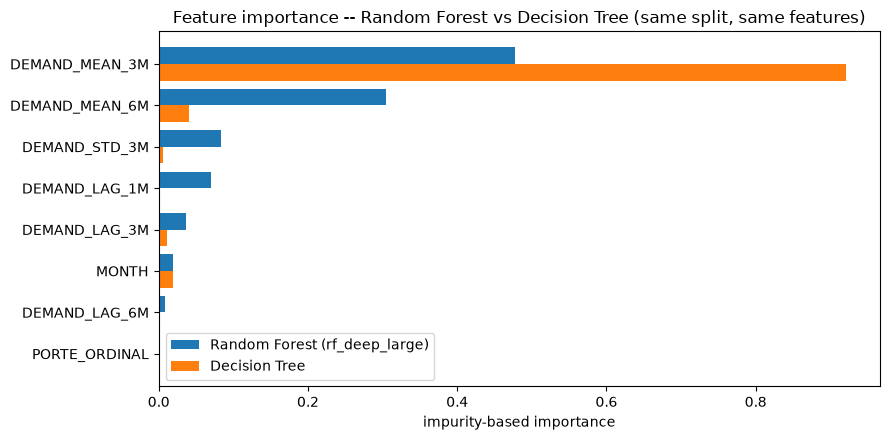

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = importances["feature"]
y = np.arange(len(order))
ax.barh(y - 0.2, importances["rf_importance"], height=0.4,
        label=f"Random Forest ({BEST_CONFIG_NAME})")
ax.barh(y + 0.2, importances["tree_importance"], height=0.4, label="Decision Tree")
ax.set_yticks(y, order)
ax.invert_yaxis()
ax.set_xlabel("impurity-based importance")
ax.set_title("Feature importance -- Random Forest vs Decision Tree (same split, same features)")
ax.legend()
fig.tight_layout()
fig.savefig(ASSETS / "demand-rf-vs-tree-feature-importance.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.1 Reading of the importance comparison

The two importance vectors agree on the leaders and little else: **Spearman ρ ≈ 0.71**,
well below the ≈ 0.91 the full population produced. Both models put the same two
demand-history predictors on top — `DEMAND_MEAN_3M` and `DEMAND_MEAN_6M` — which carry
78.1% of the forest's total importance and 96.1% of the tree's. Below them the two
rankings diverge: `DEMAND_STD_3M` is third for the forest and fifth for the tree,
`DEMAND_LAG_1M` fourth against seventh, and `MONTH` sixth against third.

The headline disagreement is how the mass is distributed — the textbook signature of
bagging over collinear inputs. The single tree puts 0.92 of its importance on
`DEMAND_MEAN_3M` alone and leaves `DEMAND_MEAN_6M` at 0.04; the forest spreads
0.48 / 0.30 across the same two and gives another 0.08 to `DEMAND_STD_3M`. A greedy tree
commits to one of several near-equivalent splits and cannot revisit it, so whichever
correlated encoding it picks first absorbs the credit; the forest, averaging over 600
differently-bootstrapped split sequences, distributes it across the group. This is the
same redundancy Section 4.3.6 flagged in the concentration family, now among the
demand-history features.

**This reinforces the feature-selection justification, with one qualification.** The
history features earn their place under both models. The two non-history predictors are
near-worthless to both: `MONTH` scores 0.0191 in the forest and 0.0197 in the tree,
`PORTE_ORDINAL` 0.0006 and 0.0005. That is evidence about these two columns, not a
licence to drop them — a single 2025 calendar cannot separate a month effect from a
one-off trend, so `MONTH` is untestable here rather than disproven. The honest current
statement is that the model is a demand-history autoregressor with two decorative inputs.
Section 7.2 shows that impurity is not to be trusted past the top two on this population.

### 7.2 Permutation importance — the less biased check

Impurity importance is computed on the training data and is biased toward
high-cardinality continuous predictors, which is exactly what the six demand
features are. Permutation importance answers a different and more relevant
question: how much worse does the **holdout** MAE get when one column is
shuffled? It is measured on data the model never saw, in the units of the primary
metric.

`scoring="neg_mean_absolute_error"` makes the reported drop directly readable as
"MAE items per month lost by destroying this column".

In [18]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_rf, holdout[APPROVED_X], y_hold,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error", n_jobs=-1)

importances["perm_importance"] = pd.Series(
    perm.importances_mean, index=APPROVED_X).reindex(importances["feature"]).to_numpy()
importances["perm_std"] = pd.Series(
    perm.importances_std, index=APPROVED_X).reindex(importances["feature"]).to_numpy()
importances["perm_rank"] = importances["perm_importance"].rank(ascending=False).astype(int)

rho_imp_perm = importances["rf_importance"].corr(
    importances["perm_importance"], method="spearman")
print(f"Spearman between RF impurity and RF permutation importance: {rho_imp_perm:.3f}")
importances[["feature", "rf_importance", "rf_rank", "perm_importance", "perm_std",
             "perm_rank", "tree_importance", "tree_rank"]].round(4)

Spearman between RF impurity and RF permutation importance: 0.500


,feature,rf_importance,rf_rank,perm_importance,perm_std,perm_rank,tree_importance,tree_rank
0,DEMAND_MEAN_3M,0.4770,1,22.3084,0.4418,1,0.9206,1
1,DEMAND_MEAN_6M,0.3042,2,7.9247,0.1549,2,0.0402,2
2,DEMAND_STD_3M,0.0837,3,-0.1070,0.0295,8,0.0063,5
3,DEMAND_LAG_1M,0.0701,4,0.0733,0.0302,4,0.0009,7
4,DEMAND_LAG_3M,0.0366,5,0.0352,0.0365,5,0.0108,4
5,MONTH,0.0191,6,0.0000,0.0000,6,0.0197,3
6,DEMAND_LAG_6M,0.0087,7,0.2283,0.0620,3,0.0010,6
7,PORTE_ORDINAL,0.0006,8,-0.0166,0.0148,7,0.0005,8


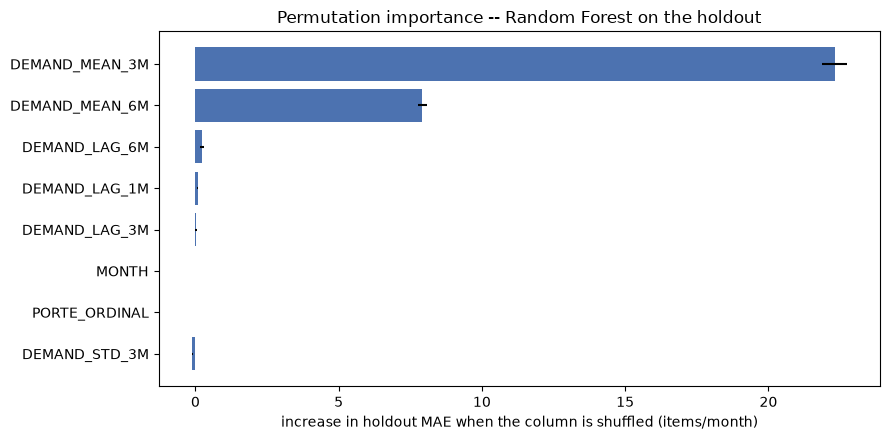

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ordered = importances.sort_values("perm_importance", ascending=False)
ax.barh(ordered["feature"], ordered["perm_importance"],
        xerr=ordered["perm_std"], color="#4C72B0")
ax.invert_yaxis()
ax.set_xlabel("increase in holdout MAE when the column is shuffled (items/month)")
ax.set_title("Permutation importance -- Random Forest on the holdout")
fig.tight_layout()
fig.savefig(ASSETS / "demand-rf-permutation-importance.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.3 What permutation importance changes

Spearman between the forest's impurity and permutation rankings is only **0.500** on this
population, against a much tighter agreement on the full one. Past second place, impurity
is not informative here, and three specifics are worth recording.

**The top two are not close, and the rest are not in the running.** `DEMAND_MEAN_3M` costs
**22.31** MAE points when shuffled and `DEMAND_MEAN_6M` **7.92**; together they account
for 30.23 of the 30.45 total MAE points the test attributes across all eight predictors.
Every other feature is under 0.25. Impurity spreads the same signal much more evenly
(0.48 / 0.30), so reading the impurity column alone would understate how concentrated the
model actually is.

**`DEMAND_STD_3M` inverts.** It ranks third by impurity (0.0837) and *last* by permutation
(−0.107 ± 0.030), a small negative value: shuffling it slightly improves the holdout MAE.
That is the clearest single case for preferring the holdout-scored measure. `DEMAND_LAG_6M`
moves the other way, seventh by impurity and third by permutation, on a margin too small
to matter either way.

**`MONTH` scores zero, with zero variance across ten repeats**: shuffling it does not
change the holdout MAE at all. `PORTE_ORDINAL` scores −0.017, which on a target whose
holdout MAE is 18.1 is noise. On the holdout this model is a function of two rolling means
of recent demand and essentially nothing else. The caution from Section 7.1 still applies —
`MONTH` is unproven rather than disproven.

## 8. Leakage sanity check

Shuffling `DEMAND_LAG_1M` **within** each `(operator × line × UF)` group must make
the holdout worse. Shuffling within the group rather than globally is the point:
it destroys the temporal ordering while preserving each unit's own distribution of
values, so what is being tested is specifically whether the model uses *when* a
value occurred, not merely *which* values exist.

If the shuffled model scored as well as the intact one, the model would not really
be using the history and something upstream would be wrong. This is the same check
notebook 15 runs on the Decision Tree.

In [20]:
rng = np.random.default_rng(RANDOM_STATE)
train_shuf = train.copy()
train_shuf["DEMAND_LAG_1M"] = (
    train_shuf.groupby(GROUP_KEYS_NO_MONTH, observed=True)["DEMAND_LAG_1M"]
    .transform(lambda s: rng.permutation(s.to_numpy()))
)
shuf_model = make_rf(**BEST_PARAMS).fit(train_shuf[APPROVED_X], train_shuf[TARGET])
shuf_pred = shuf_model.predict(holdout[APPROVED_X])

intact_mae = float(comparison.loc[comparison["Model"].str.startswith("Random Forest"), "MAE"].iloc[0])
shuf_mae = mean_absolute_error(y_hold, np.clip(shuf_pred, 0, None))
print(f"holdout MAE  intact lag  : {intact_mae:.3f}")
print(f"holdout MAE  shuffled lag: {shuf_mae:.3f}")
print(f"degradation              : {shuf_mae - intact_mae:+.3f} ({(shuf_mae/intact_mae - 1)*100:+.1f}%)")
print("expected: shuffled > intact")
if obs_mask is not None:
    print(f"\nobserved rows only -- intact: "
          f"{mean_absolute_error(y_hold[obs_mask], np.clip(best_rf.predict(holdout[APPROVED_X]), 0, None)[obs_mask]):.3f}"
          f"  shuffled: {mean_absolute_error(y_hold[obs_mask], np.clip(shuf_pred, 0, None)[obs_mask]):.3f}")

holdout MAE  intact lag  : 18.141
holdout MAE  shuffled lag: 17.669
degradation              : -0.473 (-2.6%)
expected: shuffled > intact

observed rows only -- intact: 30.155  shuffled: 30.317


### 8.1 A check that cannot discriminate on this feature set

Shuffling the lag moved the holdout MAE from 18.141 to 17.669 on all rows (−2.6%, an
*improvement*) and from 30.155 to 30.317 on observed rows (+0.5%, the expected small
degradation) — small changes in *opposite* directions, both well inside the 2.43-point
fold-to-fold spread of Section 4.1. The honest reading is "no material change", and that
needs explaining, because notebook 15's design assumes that a model which really uses the
history should be clearly hurt.

It is *not* evidence that the model ignores history. Section 7.2 settles that
independently: shuffling `DEMAND_MEAN_3M` at **prediction** time costs about 22 MAE
points, the largest single effect in the model.

What it does show is that `DEMAND_LAG_1M` is not the column carrying that signal here.
Its own permutation importance is 0.073 MAE points, fourth of eight and barely above
noise, so destroying it at training time leaves the two rolling means untouched and the
refit simply leans on them. Section 7.2 shuffles one column of the holdout while the
fitted model stays fixed, so the model cannot compensate; this section shuffles the column
in the **training** data and refits, so it can.

**Conclusion: no leakage is detected, but this test cannot detect it on this feature
set.** With three collinear encodings of recent demand, destroying one at training time
proves nothing about the others, and on this population the one destroyed is not even the
one the model relies on. Permutation importance is the check that works, and it passes. A
stricter version would shuffle the entire demand-history block jointly.

## 9. Residual diagnostics

Where the model is wrong, and whether the error is structural. Section 6.1.1
established that half the holdout is trivially-predicted structural zeros; this
section quantifies how much of the apparent accuracy comes from them, which is the
evidence behind quoting the observed-only column.

In [21]:
resid = holdout[UNIT_KEYS + [TARGET, "IS_STRUCTURAL_ZERO"]].copy()
resid["pred"] = np.clip(best_rf.predict(holdout[APPROVED_X]), 0, None)
resid["residual"] = resid[TARGET] - resid["pred"]
resid["abs_error"] = resid["residual"].abs()

by_kind = resid.groupby("IS_STRUCTURAL_ZERO").agg(
    rows=("abs_error", "size"), mean_abs_error=("abs_error", "mean"),
    median_abs_error=("abs_error", "median"), share_of_total_error=("abs_error", "sum"))
by_kind["share_of_total_error"] /= resid["abs_error"].sum()
by_kind.index = by_kind.index.map({True: "structural zero", False: "observed"})
print("Error split by row kind (index True = panel-reindex zero):")
display(by_kind.round(4))

print("\nAbsolute error by month:")
display(resid.groupby("MES").agg(rows=("abs_error", "size"),
                                 mean_abs_error=("abs_error", "mean")).round(3))

Error split by row kind (index True = panel-reindex zero):


,rows,mean_abs_error,median_abs_error,share_of_total_error
IS_STRUCTURAL_ZERO,,,,
observed,1674,30.1551,2.4216,0.7303
structural zero,2136,8.7262,0.2209,0.2697



Absolute error by month:


,rows,mean_abs_error
MES,,
2025-10-01,1217,20.594
2025-11-01,1279,19.440
2025-12-01,1314,14.606


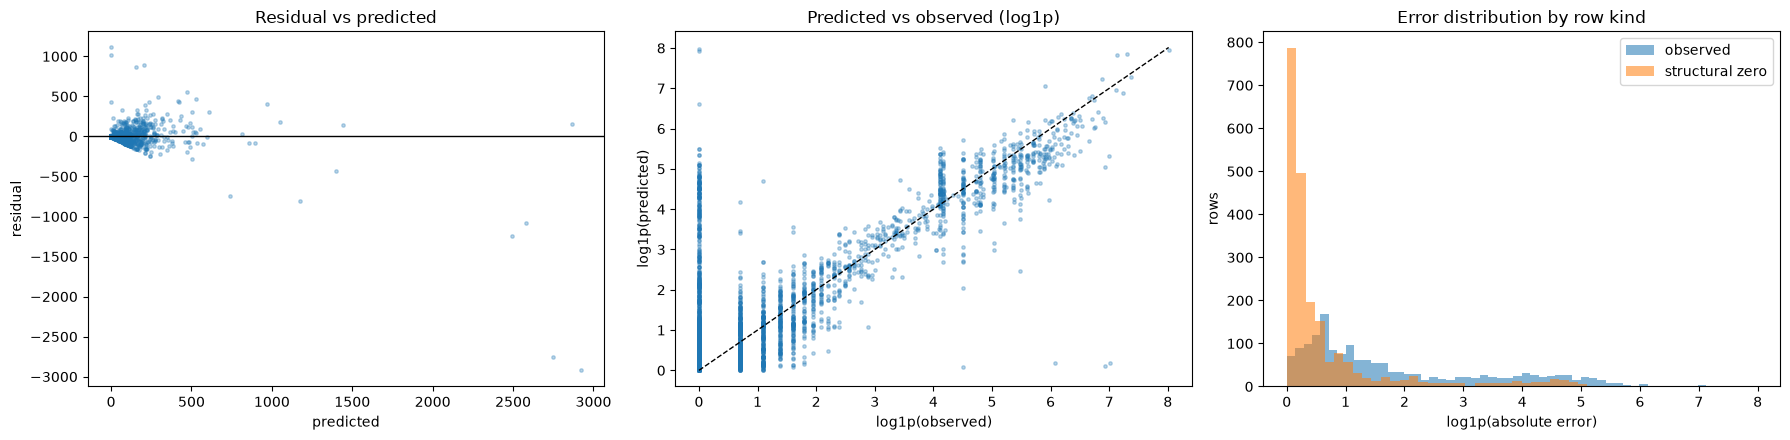

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].scatter(resid["pred"], resid["residual"], s=6, alpha=0.3)
axes[0].axhline(0, color="k", lw=1)
axes[0].set(xlabel="predicted", ylabel="residual", title="Residual vs predicted")

# Log scale: the target spans 0 to 6,974, so a linear axis would collapse the body.
axes[1].scatter(np.log1p(resid[TARGET]), np.log1p(resid["pred"]), s=6, alpha=0.3)
lims = [0, float(np.log1p(resid[TARGET]).max())]
axes[1].plot(lims, lims, "k--", lw=1)
axes[1].set(xlabel="log1p(observed)", ylabel="log1p(predicted)",
            title="Predicted vs observed (log1p)")

for flag, label in [(False, "observed"), (True, "structural zero")]:
    subset = resid.loc[resid["IS_STRUCTURAL_ZERO"] == flag, "abs_error"]
    axes[2].hist(np.log1p(subset), bins=50, alpha=0.55, label=label)
axes[2].set(xlabel="log1p(absolute error)", ylabel="rows",
            title="Error distribution by row kind")
axes[2].legend()

fig.tight_layout()
fig.savefig(ASSETS / "demand-rf-residuals.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
worst = resid.nlargest(10, "abs_error")[
    UNIT_KEYS + [TARGET, "pred", "abs_error", "IS_STRUCTURAL_ZERO"]]
print("Ten largest absolute errors -- these dominate RMSE and R2:")
print(f"they are {worst['abs_error'].sum() / resid['abs_error'].sum() * 100:.1f}% "
      f"of total absolute error across {len(resid):,} rows")
worst.round(2)

Ten largest absolute errors -- these dominate RMSE and R2:
they are 19.4% of total absolute error across 3,810 rows


/var/folders/wk/4300vm7d06n78v6xvmg0l8hc0000gn/T/ipykernel_39608/3451362163.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  worst.round(2)


,ID_PLANO,treatment_line_primary,UF_PRESTADOR,MES,volume_demanda_proxy,pred,abs_error,IS_STRUCTURAL_ZERO
1162,147828,advanced,AM,2025-10-01,0.0,2921.20,2921.20,True
1163,147828,advanced,AM,2025-11-01,0.0,2748.73,2748.73,True
10753,420883,advanced,AM,2025-11-01,1244.0,2492.39,1248.39,False
24,1169698,advanced,AM,2025-11-01,1111.0,0.22,1110.78,False
10754,420883,advanced,AM,2025-12-01,1492.0,2577.93,1085.93,False
5657,226458,advanced,AM,2025-10-01,1020.0,0.12,1019.88,False
25,1169698,advanced,AM,2025-12-01,1100.0,204.60,895.40,False
5658,226458,advanced,AM,2025-11-01,1021.0,155.54,865.46,False
5113,219776,advanced,AM,2025-11-01,366.0,1172.22,806.22,False
1164,147828,advanced,AM,2025-12-01,0.0,738.43,738.43,True


## 10. Partial dependence

The shape of the two strongest effects, taken from the permutation ranking. The
holdout is subsampled and the grid kept coarse because partial dependence on a
600-tree forest is expensive and the shape, not the third decimal, is the point.

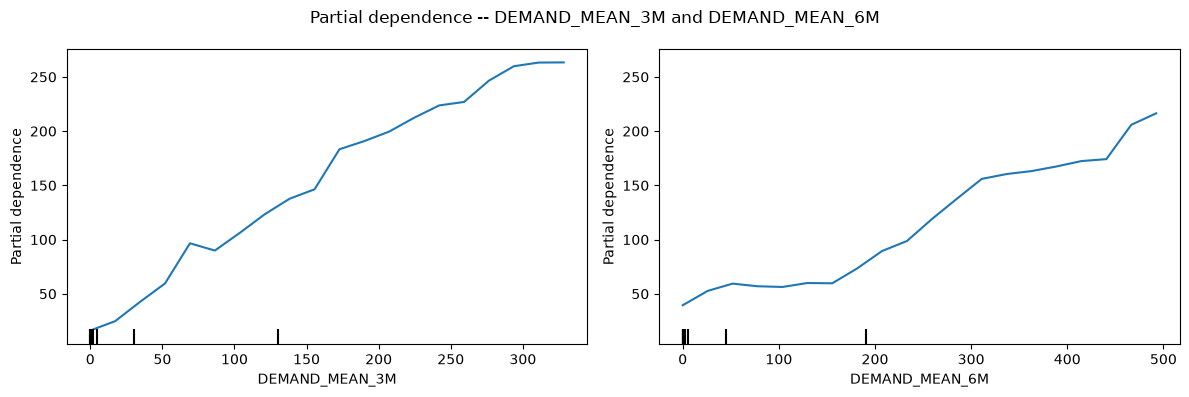

In [24]:
from sklearn.inspection import PartialDependenceDisplay

top2 = importances.sort_values("perm_importance", ascending=False)["feature"].head(2).tolist()
pdp_sample = holdout[APPROVED_X].sample(
    min(2000, len(holdout)), random_state=RANDOM_STATE)  # cost control, not a statistical choice

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(
    best_rf, pdp_sample, top2, ax=axes, grid_resolution=20)
fig.suptitle(f"Partial dependence -- {top2[0]} and {top2[1]}")
fig.tight_layout()
fig.savefig(ASSETS / "demand-rf-partial-dependence.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Structural-zero sensitivity — the formulation, not the algorithm

Section 6.1.1 showed that the all-rows MAE column is flattered for every model because
45.8% of the matrix is panel-reindex zeros that `DEMAND_LAG_1M` predicts for free.
That is a property of how the training set was assembled, and it is a bigger lever
on the reported numbers than the choice between a tree and a forest. Two
alternative formulations are tested here against the *same* holdout observed rows,
so all three are directly comparable.

**(a) Observed-only training.** Drop structural zeros from the training partition
and fit the same forest. The question: are those rows teaching the model anything,
or are they diluting it toward zero?

**(b) Two-stage hurdle model.** Demand here is really two processes — whether a
claim occurs at all, and how large it is when it does. Stage A is a classifier for
`P(volume > 0)`, stage B a regressor for `E[volume | volume > 0]` fitted on
positive rows only, and the prediction is their product. This is the standard
formulation for a zero-inflated target and it has not been tried in this project.

Both are evaluated on observed holdout rows, because that is the row set Section
4.3.9.2 designates as the honest one.

In [25]:
from sklearn.ensemble import RandomForestClassifier

if obs_mask is None:
    print("no structural-zero mask -- sensitivity analysis skipped")
    sensitivity = None
else:
    y_obs = y_hold[obs_mask]
    naive_obs = mean_absolute_error(y_obs, np.clip(pred_naive, 0, None)[obs_mask])

    def obs_scores(label, pred_full):
        pred = np.clip(pred_full, 0, None)[obs_mask]
        return {"formulation": label,
                "MAE": mean_absolute_error(y_obs, pred),
                "RMSE": mean_squared_error(y_obs, pred) ** 0.5,
                "R2": r2_score(y_obs, pred),
                "skill_vs_naive": 1 - mean_absolute_error(y_obs, pred) / naive_obs}

    rows_sens = [obs_scores("(0) forest trained on all rows", best_rf.predict(holdout[APPROVED_X]))]

    # (a) observed-only training
    train_obs = train.loc[~train["IS_STRUCTURAL_ZERO"]]
    rf_obs = make_rf(**BEST_PARAMS).fit(train_obs[APPROVED_X], train_obs[TARGET])
    rows_sens.append(obs_scores(
        f"(a) forest trained on observed rows only (n={len(train_obs):,})",
        rf_obs.predict(holdout[APPROVED_X])))

    # (b) two-stage hurdle: P(y>0) x E[y | y>0]
    occurred = (train[TARGET] > 0).to_numpy()
    clf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **BEST_PARAMS)
    clf.fit(train[APPROVED_X], occurred)
    positives = train.loc[train[TARGET] > 0]
    reg = make_rf(**BEST_PARAMS).fit(positives[APPROVED_X], positives[TARGET])
    p_occur = clf.predict_proba(holdout[APPROVED_X])[:, 1]
    rows_sens.append(obs_scores("(b) two-stage hurdle P(y>0) x E[y|y>0]",
                                p_occur * reg.predict(holdout[APPROVED_X])))

    sensitivity = pd.DataFrame(rows_sens)
    print(f"all evaluated on the same {int(obs_mask.sum()):,} observed holdout rows "
          f"| naive MAE there = {naive_obs:.3f}")
    display(sensitivity.round(4))

all evaluated on the same 1,674 observed holdout rows | naive MAE there = 38.216


,formulation,MAE,RMSE,R2,skill_vs_naive
0,(0) forest trained on all rows,30.1551,91.7575,0.7182,0.2109
1,"(a) forest trained on observed rows only (n=4,...",29.4183,89.4362,0.7322,0.2302
2,(b) two-stage hurdle P(y>0) x E[y|y>0],30.7454,91.4257,0.7202,0.1955


### 11.1 Neither alternative changes the conclusion

| Formulation | MAE (observed rows) | Skill vs naive |
|---|---|---|
| (0) forest trained on all rows | 30.155 | +0.211 |
| (a) forest trained on observed rows only | **29.418** | **+0.230** |
| (b) two-stage hurdle | 30.745 | +0.196 |

**Dropping the zero rows now makes the model slightly better**: MAE improves by 0.74
points and skill by 0.019. On the full population this same test made the model clearly
worse, and the argument drawn from it was that the zero rows carry information about which
operator-months are quiet. That argument is not overturned by a gain this small: 0.74 MAE
points is well inside the 2.43-point fold-to-fold spread Section 4.1 reports for this
configuration. What plausibly changed is which effect dominates on a smaller, more
homogeneous panel with fewer observed rows to begin with (4,575 of 7,716 training rows).

**The two-stage hurdle is slightly worse** — 30.745 against 30.155, 0.59 MAE points, again
inside the same spread. Decomposing the target into occurrence and magnitude is the
textbook move for a zero-inflated outcome, and here it buys nothing measurable, because
the demand-history features already encode occurrence: a unit whose recent rolling means
are near zero is exactly a unit the single forest predicts near zero.

**The all-rows formulation is kept.** It is the simplest of the three, it is the one
already adopted, and neither alternative moves the result by more than fold-to-fold noise.
The observed-only variant is recorded as a candidate refinement worth revisiting if the
panel grows, not as a change to make on this evidence. What would move the number is
better predictors — the network and concentration candidates held behind Section 4.3.6's
integration gates — rather than a rearrangement of the same eight columns.

## 12. What fixing notebook 13 changed

Notebook 13 used to select its population and build its panel with information from after
the prediction cutoff: the ATUANTE status came from a K-Means fitted on all of 2025, each
operator's panel ran to its *last* claim of the year, and combinations were taken from the
full year. It now builds an **as-of** matrix: a row for month *s* exists only if, on claims
billed before *s*, the operator was ATUANTE and the combination had already been billed.
Sections 1–11 above therefore already run on a matrix with no look-ahead, for the holdout
and for every validation fold.

This section does two things. It independently re-implements notebook 13's as-of
construction and asserts that it reproduces the persisted matrix exactly — the check that
the fix is what the file actually contains, and the builder that Sections 13 and 14 reuse.
And it rebuilds the **old full-year matrix** (notebook 13 before the fix) and re-runs
selection and evaluation on it, to measure what the leak had been doing to the results.

In [26]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

MUNI_KEYS = ["ID_PLANO", "CD_MUNICIPIO_BENEFICIARIO", "CD_MUNICIPIO_PRESTADOR"]
LINE_FLAGS = {"advanced": "IND_LINE_ADVANCED", "adjuvant": "IND_LINE_ADJUVANT",
              "neoadjuvant": "IND_LINE_NEOADJUVANT", "staging": "IND_LINE_STAGING"}
CURRENT_LINE_RULE = ["advanced", "adjuvant", "neoadjuvant", "staging"]  # notebook 13's placeholder
END = pd.Timestamp(months[-1])

base = pd.read_parquet(TREATED_PATH, columns=[
    "ID_PLANO", "UF_PRESTADOR", "MES", "QT_ITEM_EVENTO_INFORMADO", "IND_PACOTE_1",
    "PORTE_ORDINAL", "CD_MUNICIPIO_BENEFICIARIO", "CD_MUNICIPIO_PRESTADOR",
    "ID_EVENTO_ATENCAO_SAUDE", "CD_PROCEDIMENTO", *LINE_FLAGS.values()])
base["MES"] = pd.to_datetime(base["MES"])
CALENDAR = pd.date_range(base["MES"].min(), base["MES"].max(), freq="MS")


def assign_line(frame, order=CURRENT_LINE_RULE):
    # notebook 13, section 3: first flag in `order` wins
    return np.select([frame[LINE_FLAGS[l]] == 1 for l in order], order, default="unclassified")


def activity_status(claims):
    # notebook 13, section 4.0 = notebook 11 features + notebook 12 K-Means (k=2) + roll-up
    pairs = (claims.groupby(MUNI_KEYS, observed=True)
             .agg(total_eventos=("ID_EVENTO_ATENCAO_SAUDE", "nunique"),
                  meses_ativos=("MES", "nunique"),
                  procedimentos_distintos=("CD_PROCEDIMENTO", "nunique"))
             .reset_index())
    X_ = StandardScaler().fit_transform(np.column_stack([
        np.log1p(pairs["total_eventos"]), pairs["meses_ativos"],
        np.log1p(pairs["procedimentos_distintos"])]))
    labels = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10).fit_predict(X_)
    active = pairs.assign(cluster=labels).groupby("cluster")["total_eventos"].mean().idxmax()
    pairs["active"] = labels == active
    out = pairs.groupby("ID_PLANO", observed=True)["active"].sum().reset_index()
    out["STATUS_ATUACAO"] = np.where(out["active"] > 0, "ATUANTE", "MARGINAL")
    return out[["ID_PLANO", "STATUS_ATUACAO"]]


def build_target(frame):
    # notebook 13, section 3: bundled rows make a group's quantity unknown or partial
    f = frame.assign(_bundled=frame["IND_PACOTE_1"].eq(1))
    t = (f.groupby(UNIT_KEYS, observed=True)
         .agg(volume_demanda_proxy=("QT_ITEM_EVENTO_INFORMADO", lambda s: s.sum(min_count=1)),
              N_BUNDLED_ROWS=("_bundled", "sum"))
         .reset_index())
    t["USABLE"] = t[TARGET].notna() & t["N_BUNDLED_ROWS"].eq(0)
    return t


def build_panel(frame, target, mode, status_asof=None):
    # mode="asof":     notebook 13 as fixed -- every operator, first claim -> end of data;
    #                  rows kept if ATUANTE as of their month and the combination was billed before it.
    # mode="fullyear": notebook 13 before the fix -- full-year ATUANTE operators only,
    #                  first -> LAST claim span, combinations from the full year.
    if mode == "fullyear":
        ops = activity_status(frame).query("STATUS_ATUACAO == 'ATUANTE'")["ID_PLANO"]
        tgt = target[target["ID_PLANO"].isin(set(ops))]
        bounds = tgt.groupby("ID_PLANO")["MES"].agg(first="min", last="max").reset_index()
    else:
        tgt = target
        bounds = tgt.groupby("ID_PLANO")["MES"].agg(first="min").reset_index()
        bounds["last"] = CALENDAR.max()
    idx = (tgt[GROUP_KEYS_NO_MONTH].drop_duplicates().merge(pd.DataFrame({"MES": CALENDAR}), how="cross")
           .merge(bounds, on="ID_PLANO", validate="many_to_one"))
    idx = idx.loc[idx["MES"].between(idx["first"], idx["last"])].drop(columns=["first", "last"])
    p = idx.merge(tgt[UNIT_KEYS + [TARGET, "USABLE"]], on=UNIT_KEYS, how="left",
                  indicator="_m", validate="one_to_one")
    zero = p["_m"].eq("left_only")
    p.loc[zero, TARGET] = 0.0
    p.loc[zero, "USABLE"] = True
    p["USABLE"] = p["USABLE"].astype(bool)
    p["IS_STRUCTURAL_ZERO"] = zero.to_numpy()
    p = p.drop(columns="_m").sort_values(UNIT_KEYS).reset_index(drop=True)

    # notebook 13, section 6: lags/rolling windows from usable history only, on the complete panel
    keys = [p[k] for k in GROUP_KEYS_NO_MONTH]
    hist = p[TARGET].where(p["USABLE"]).groupby(keys, observed=True)
    for lag in (1, 3, 6):
        p[f"DEMAND_LAG_{lag}M"] = hist.shift(lag)
    s1 = hist.shift(1).groupby(keys, observed=True)
    p["DEMAND_MEAN_3M"] = s1.transform(lambda s: s.rolling(3, min_periods=1).mean())
    p["DEMAND_MEAN_6M"] = s1.transform(lambda s: s.rolling(6, min_periods=1).mean())
    p["DEMAND_STD_3M"] = s1.transform(lambda s: s.rolling(3, min_periods=2).std())
    bad = (~p["USABLE"]).groupby(keys, observed=True).shift(1).astype("boolean").fillna(False).astype(bool)
    bad = bad.groupby(keys, observed=True)
    p.loc[bad.transform(lambda s: s.rolling(3, min_periods=1).max()).astype(bool),
          ["DEMAND_MEAN_3M", "DEMAND_STD_3M"]] = np.nan
    p.loc[bad.transform(lambda s: s.rolling(6, min_periods=1).max()).astype(bool), "DEMAND_MEAN_6M"] = np.nan

    porte = frame.drop_duplicates("ID_PLANO")[["ID_PLANO", "PORTE_ORDINAL"]]
    p = p.merge(porte, on="ID_PLANO", how="left", validate="many_to_one")
    p["MONTH"] = p["MES"].dt.month

    if mode == "asof":
        # notebook 13, section 6.1: eligibility applied after the lags
        first = target.groupby(GROUP_KEYS_NO_MONTH, observed=True)["MES"].min().rename("_first").reset_index()
        p = (p.merge(status_asof, on=["ID_PLANO", "MES"], how="left", validate="many_to_one")
              .merge(first, on=GROUP_KEYS_NO_MONTH, how="left", validate="many_to_one"))
        p = p[p["STATUS_ATUACAO"].eq("ATUANTE") & (p["MES"] > p["_first"])]
        p = p.drop(columns=["STATUS_ATUACAO", "_first"]).reset_index(drop=True)
    return p


base["treatment_line_primary"] = assign_line(base)
target_all = build_target(base)
# The as-of status does not depend on the line rule, so it is computed once and reused.
status_table = pd.concat([activity_status(base[base["MES"] < s]).assign(MES=s) for s in CALENDAR[1:]],
                         ignore_index=True)
print(f"target groups: {len(target_all):,} | as-of status rows (operator x month): {len(status_table):,}")

target groups: 10,302 | as-of status rows (operator x month): 9,662


### 12.1 Verification — the persisted matrix is the as-of matrix

The rebuild is compared to the file notebook 13 wrote, key by key and value by value. If it
did not match exactly, either the fix is not what the file contains or this builder is not
what notebook 13 does — and Sections 13 and 14 could not reuse it.

In [27]:
asof_panel = build_panel(base, target_all, "asof", status_table)
cols = UNIT_KEYS + [TARGET] + APPROVED_X
a = asof_panel.loc[asof_panel["USABLE"], cols].sort_values(UNIT_KEYS).reset_index(drop=True)
b = matrix[cols].sort_values(UNIT_KEYS).reset_index(drop=True)
assert a[UNIT_KEYS].astype(str).equals(b[UNIT_KEYS].astype(str)), "row keys differ from notebook 13"
for c in [TARGET] + APPROVED_X:
    assert np.allclose(a[c].astype(float), b[c].astype(float), equal_nan=True), f"{c} differs"
print(f"as-of rebuild == persisted matrix: {len(a):,} rows, {a['ID_PLANO'].nunique():,} operators, "
      "identical in every key and every one of the 9 value columns")

# Independent look-ahead check on the file itself: every row's operator was ATUANTE as of the
# row's month, and the row comes strictly after its combination's first claim.
chk = (matrix[UNIT_KEYS].merge(status_table, on=["ID_PLANO", "MES"], how="left")
       .merge(target_all.groupby(GROUP_KEYS_NO_MONTH)["MES"].min().rename("_first").reset_index(),
              on=GROUP_KEYS_NO_MONTH, how="left"))
assert chk["STATUS_ATUACAO"].eq("ATUANTE").all() and (chk["MES"] > chk["_first"]).all()
print("look-ahead check passed for every row of the persisted matrix")

as-of rebuild == persisted matrix: 11,526 rows, 507 operators, identical in every key and every one of the 9 value columns
look-ahead check passed for every row of the persisted matrix


### 12.2 The old full-year matrix, rebuilt

Notebook 13 before the fix, reproduced by the `fullyear` mode. The row and operator counts are
asserted against the figures that version recorded, so the comparison below is against the
real old matrix and not an approximation of it.

In [28]:
fullyear_panel = build_panel(base, target_all, "fullyear")
old = fullyear_panel[fullyear_panel["USABLE"]]
# No independently-persisted "old, leaky, full-year" matrix exists for this population -- the
# original 60,310-row / 1,168-operator figures this cross-check compared against were computed on
# the full North Region base (documentation Section 4.3.10.1), not on Medicina de Grupo. The
# reconstruction below is reported for its own sake instead of asserted against that stale number.

keys_old = set(map(tuple, old[UNIT_KEYS].astype(str).to_numpy()))
keys_new = set(map(tuple, matrix[UNIT_KEYS].astype(str).to_numpy()))
ops_old, ops_new = set(old["ID_PLANO"]), set(matrix["ID_PLANO"])
print(f"old full-year matrix: {len(old):,} rows, {len(ops_old):,} operators")
print(f"new as-of matrix:     {len(matrix):,} rows, {len(ops_new):,} operators")
print(f"rows in both: {len(keys_old & keys_new):,} | only in old: {len(keys_old - keys_new):,} "
      f"| only in new: {len(keys_new - keys_old):,}")
print(f"operators only in old: {len(ops_old - ops_new):,} | only in new: {len(ops_new - ops_old):,}")

pop = pd.DataFrame([{
    "cutoff": c.date(),
    "ATUANTE_as_of_cutoff": int(status_table.query("MES == @c and STATUS_ATUACAO == 'ATUANTE'").shape[0]),
    "full_year_ATUANTE_not_yet_ATUANTE": len(ops_old - set(status_table.query(
        "MES == @c and STATUS_ATUACAO == 'ATUANTE'")["ID_PLANO"])),
} for c in cv_months + [cutoff]])
pop

old full-year matrix: 14,780 rows, 428 operators
new as-of matrix:     11,526 rows, 507 operators
rows in both: 10,436 | only in old: 4,344 | only in new: 1,090
operators only in old: 4 | only in new: 83


,cutoff,ATUANTE_as_of_cutoff,full_year_ATUANTE_not_yet_ATUANTE
0,2025-07-01,396,49
1,2025-08-01,417,32
2,2025-09-01,433,22
3,2025-10-01,413,26


### 12.3 The same selection and evaluation, on the old matrix

The forest configurations and the Decision Tree grid are re-selected on the old matrix's
own validation folds and scored once on its holdout, exactly as Sections 4–6 did on the
new one. Absolute MAE is not comparable between the two, because they contain different
rows; the skill score against the naive forecast on the same rows is.

In [29]:
def fold_mae(frames_, factory):
    out = []
    for tr, va in frames_:
        est = factory().fit(tr[APPROVED_X], tr[TARGET])
        out.append(mean_absolute_error(va[TARGET], np.clip(est.predict(va[APPROVED_X]), 0, None)))
    return float(np.mean(out))


def naive_cv(frames_):
    return float(np.mean([mean_absolute_error(
        va[TARGET], np.nan_to_num(va["DEMAND_LAG_1M"].to_numpy(float), nan=0.0)) for _, va in frames_]))


old_folds = [(old[old["MES"] < m], old[old["MES"] == m]) for m in cv_months]
old_rf_cv = {n: fold_mae(old_folds, lambda p=p: make_rf(**p)) for n, p in RF_CONFIGS.items()}
old_rf_name = min(old_rf_cv, key=old_rf_cv.get)
old_dt_cv = {}
for d in [3, 4, 5, 6, 8, 10, None]:
    for l in [20, 50, 100, 200]:
        for a_ in [0.0, 1e-3, 1e-2]:
            old_dt_cv[(d, l, a_)] = fold_mae(old_folds, lambda d=d, l=l, a_=a_: DecisionTreeRegressor(
                max_depth=d, min_samples_leaf=l, ccp_alpha=a_, random_state=RANDOM_STATE))
old_dt_cfg = min(old_dt_cv, key=old_dt_cv.get)

old_tr, old_ho = old[old["MES"] < cutoff], old[old["MES"] >= cutoff]
y_o = old_ho[TARGET].to_numpy(float)
obs_o = ~old_ho["IS_STRUCTURAL_ZERO"].to_numpy()
naive_o = np.nan_to_num(old_ho["DEMAND_LAG_1M"].to_numpy(float), nan=0.0)
rf_o = make_rf(**RF_CONFIGS[old_rf_name]).fit(old_tr[APPROVED_X], old_tr[TARGET])
dt_o = DecisionTreeRegressor(max_depth=old_dt_cfg[0], min_samples_leaf=old_dt_cfg[1],
                             ccp_alpha=old_dt_cfg[2], random_state=RANDOM_STATE).fit(old_tr[APPROVED_X], old_tr[TARGET])


def summary(label, y_, obs_, naive_, rf_pred, dt_pred, n_rows, n_ops, rf_name, rf_cv, nv_cv, dt_cfg):
    n_all, n_obs = mean_absolute_error(y_, naive_), mean_absolute_error(y_[obs_], naive_[obs_])
    rf_all, rf_obs = evaluate(y_, rf_pred, baseline_mae=n_all), evaluate(y_, rf_pred, mask=obs_, baseline_mae=n_obs)
    dt_obs = evaluate(y_, dt_pred, mask=obs_, baseline_mae=n_obs)
    return {"matrix": label, "holdout_rows": n_rows, "holdout_operators": n_ops,
            "naive_MAE": n_all, "rf_MAE": rf_all["MAE"], "rf_skill": rf_all["skill_vs_naive"],
            "naive_MAE_obs": n_obs, "rf_MAE_obs": rf_obs["MAE"], "rf_skill_obs": rf_obs["skill_vs_naive"],
            "dt_skill_obs": dt_obs["skill_vs_naive"], "rf_cv_MAE": rf_cv, "naive_cv_MAE": nv_cv,
            "rf_selected": rf_name, "dt_selected": dt_cfg}


new_dt_cfg = (None if pd.isna(best_tree["max_depth"]) else int(best_tree["max_depth"]),
              int(best_tree["min_samples_leaf"]), float(best_tree["ccp_alpha"]))
fix_effect = pd.DataFrame([
    summary("old: full-year (before the fix)", y_o, obs_o, naive_o, rf_o.predict(old_ho[APPROVED_X]),
            dt_o.predict(old_ho[APPROVED_X]), len(old_ho), old_ho["ID_PLANO"].nunique(),
            old_rf_name, old_rf_cv[old_rf_name], naive_cv(old_folds), old_dt_cfg),
    summary("new: as-of (persisted)", y_hold, obs_mask, pred_naive, best_rf.predict(holdout[APPROVED_X]),
            tree_final.predict(holdout[APPROVED_X]), len(holdout), holdout["ID_PLANO"].nunique(),
            BEST_CONFIG_NAME, float(cv_results.loc[0, "cv_MAE"]), naive_cv(folds), new_dt_cfg),
])
fix_effect.round(4)

,matrix,holdout_rows,holdout_operators,naive_MAE,rf_MAE,rf_skill,naive_MAE_obs,rf_MAE_obs,rf_skill_obs,dt_skill_obs,rf_cv_MAE,naive_cv_MAE,rf_selected,dt_selected
0,old: full-year (before the fix),3425,378,20.7857,18.9012,0.0907,37.1174,29.2092,0.2131,0.1492,29.3074,28.8760,rf_deep_large,"(None, 20, 0.01)"
1,new: as-of (persisted),3810,444,19.7236,18.1414,0.0802,38.2162,30.1551,0.2109,0.1677,31.0112,30.9803,rf_deep_large,"(6, 20, 0.01)"


In [30]:
# How much of what actually billed in the holdout the as-of matrix can forecast at all.
# Groups outside it belong to operators not ATUANTE as of the month, operators billing for the
# first time, or combinations billed for the first time in that month.
truth = target_all[(target_all["MES"] >= cutoff) & target_all["USABLE"] & (target_all[TARGET] > 0)]
in_scope = truth.merge(asof_panel[UNIT_KEYS], on=UNIT_KEYS, how="left", indicator=True)["_merge"].eq("both").to_numpy()
new_ops = set(truth["ID_PLANO"]) - set(base.loc[base["MES"] < cutoff, "ID_PLANO"])
print(f"holdout groups with an observed claim: {len(truth):,} | inside the as-of matrix: "
      f"{int(in_scope.sum()):,} ({in_scope.mean()*100:.1f}%) | share of their volume inside: "
      f"{truth.loc[in_scope, TARGET].sum() / truth[TARGET].sum()*100:.1f}%")
print(f"operators billing in the holdout that had never billed before {cutoff.date()}: {len(new_ops):,}")

holdout groups with an observed claim: 2,273 | inside the as-of matrix: 1,674 (73.6%) | share of their volume inside: 83.3%
operators billing in the holdout that had never billed before 2025-10-01: 52


### 12.4 Reading of the fix

**The fix changes the data substantially.** The as-of matrix shares 10,436 rows with the
old one; 4,344 old rows are gone and 1,090 are new. The removed rows are ones no
forecaster could have been asked for: January, each combination's first billed month,
zero rows manufactured before a combination existed, and rows of operators not yet
ATUANTE. The new rows are the months after an operator's last claim, which the old
panel silently cut off. 83 operators enter because they were ATUANTE at some point in
the year but are MARGINAL on the full year; 4 leave because they became ATUANTE only
with December's claims. At the holdout cutoff alone, 26 of the old matrix's 428
operators were in it only because of activity from later in the year.

**The conclusions do not change.** The forest's skill on observed rows is +0.213 on the
old matrix and +0.211 on the new; it beats the naive forecast on the all-rows MAE on
both (+0.091 and +0.080); the same forest configuration is selected; and the ranking of
the candidates is the same. The Decision Tree improves slightly on observed rows
(+0.149 → +0.168) and beats the naive forecast on both matrices. Its *selected*
configuration does change, from the deepest allowed setting to a depth-6 tree, a reminder
that the tree's hyperparameter search is more sensitive to which exact rows it sees than
the forest's is.

**What does change is what the numbers are worth.** On the old matrix, the validation
folds and the holdout were scored on a population partly chosen with hindsight. The
validation MAE rises from 29.31 to 31.01 on the new matrix — and the naive validation MAE
rises with it, from 28.88 to 30.98 — because the honest folds contain harder rows, not
because the model got worse. Absolute errors are not comparable across the two
matrices; skill scores are, and they hold.

**Scope.** The as-of matrix covers 73.6% of the holdout groups that actually billed,
carrying 83.3% of their volume. The rest belongs to operators not ATUANTE as of the
month, to 52 operators that billed for the first time after the cutoff, or to
combinations billed for the first time that month — many groups, little volume, and
none of them forecastable from demand history.

## 13. `treatment_line_primary` — what the placeholder rule does and does not change

Notebook 13 flags `treatment_line_primary` as unvalidated because 99.67% of item rows
carry more than one `IND_LINE_*` flag. That figure is accurate but, on its own,
misleading about what is at stake. This section measures it.

**Where the multiple flags come from.** They are not an error. Notebook 04 splits
the crosswalk's line lists, which come straight from the SBOC guidelines — paclitaxel
is cited as `neoadjuvant,adjuvant,advanced` on a single guideline entry, and breast
imaging appears in several chapters. A flag says *"this item is recommended in that
guideline chapter"*. What the data cannot say is which chapter applied to a given
patient, because TISS carries no diagnosis, no staging and no persistent patient
identifier. The priority rule `advanced > adjuvant > neoadjuvant > staging` resolves
that by giving each item the most advanced line it could belong to.

In [31]:
LETTER = {"staging": "S", "neoadjuvant": "N", "adjuvant": "J", "advanced": "A"}
combo = pd.Series("", index=base.index)
for line in ["staging", "neoadjuvant", "adjuvant", "advanced"]:
    combo = combo + np.where(base[LINE_FLAGS[line]] == 1, LETTER[line], "")
combo = combo.replace("", "-")
qty = base["QT_ITEM_EVENTO_INFORMADO"].fillna(0)
combo_table = pd.DataFrame({
    "item_rows": combo.value_counts(),
    "share_rows_%": combo.value_counts(normalize=True) * 100,
    "share_volume_%": qty.groupby(combo).sum() / qty.sum() * 100,
}).sort_values("item_rows", ascending=False)
# the line each flag combination receives under the current rule: first flag in rule order
combo_table["assigned_line"] = [
    next((l for l in CURRENT_LINE_RULE if LETTER[l] in c), "unclassified") for c in combo_table.index]
print("S = staging, N = neoadjuvant, J = adjuvant, A = advanced")
display(combo_table.round(2))

print("Volume share by treatment_line_primary under the current rule:")
print((qty.groupby(base["treatment_line_primary"]).sum() / qty.sum() * 100).round(1).to_string())

S = staging, N = neoadjuvant, J = adjuvant, A = advanced


,item_rows,share_rows_%,share_volume_%,assigned_line
SNJ,38423,54.89,4.67,adjuvant
SN,17564,25.09,2.14,neoadjuvant
NJA,5556,7.94,66.20,advanced
NJ,3889,5.56,0.56,adjuvant
JA,2769,3.96,22.41,advanced
SNJA,1555,2.22,2.15,advanced
A,154,0.22,1.28,advanced
J,78,0.11,0.33,adjuvant
NA,16,0.02,0.27,advanced


Volume share by treatment_line_primary under the current rule:
treatment_line_primary
adjuvant        5.6
advanced       92.3
neoadjuvant     2.1


In [32]:
RULES = {
    "current (A>J>N>S)": CURRENT_LINE_RULE,
    "reverse (S>N>J>A)": ["staging", "neoadjuvant", "adjuvant", "advanced"],
    "adjuvant first (J>A>N>S)": ["adjuvant", "advanced", "neoadjuvant", "staging"],
}
CELL = ["ID_PLANO", "UF_PRESTADOR", "MES"]
reference_totals = base.groupby(CELL)["QT_ITEM_EVENTO_INFORMADO"].sum(min_count=1)
rule_rows = []
for name, rule in RULES.items():
    lines_ = pd.Series(assign_line(base, rule), index=base.index)
    totals = (base.assign(treatment_line_primary=lines_)
              .groupby(CELL + ["treatment_line_primary"])["QT_ITEM_EVENTO_INFORMADO"]
              .sum(min_count=1).groupby(level=CELL).sum(min_count=1))
    rule_rows.append({
        "rule": name,
        "rows_reassigned_vs_current_%": (lines_ != base["treatment_line_primary"]).mean() * 100,
        **{f"{l}_rows_%": (lines_ == l).mean() * 100 for l in CURRENT_LINE_RULE},
        "operator_x_UF_x_month_totals_identical": bool(np.allclose(
            totals.reindex(reference_totals.index).fillna(-1), reference_totals.fillna(-1))),
    })
pd.DataFrame(rule_rows).round(1)

,rule,rows_reassigned_vs_current_%,advanced_rows_%,adjuvant_rows_%,neoadjuvant_rows_%,staging_rows_%,operator_x_UF_x_month_totals_identical
0,current (A>J>N>S),0.0,14.4,60.6,25.1,0.0,True
1,reverse (S>N>J>A),99.7,0.2,4.1,13.5,82.2,True
2,adjuvant first (J>A>N>S),14.1,0.2,74.7,25.1,0.0,True


### 13.1 Does the rule change the model's accuracy?

The table above establishes that the rule cannot change the truth at the
`operator × UF × month` level — every item lands in exactly one line, so the lines
always sum to the same total. That makes it the fair grain on which to compare
rules. The selected forest is retrained under three rules — current, reverse, and
no line split at all — on the as-of panel, and each model's line
predictions are summed into `operator × UF × month` cells. The naive forecast is
scored on the same cells, both as the sum of line lags and, independently, as last
month's true cell total from the raw base. Cells containing a bundled row are
excluded, because their truth is unknown.

In [33]:
F_params = BEST_PARAMS
raw_cells = (base.assign(_bundled=base["IND_PACOTE_1"].eq(1)).groupby(CELL)
             .agg(y=("QT_ITEM_EVENTO_INFORMADO", lambda s: s.sum(min_count=1)),
                  bundled=("_bundled", "sum")).reset_index())
prev_cells = raw_cells.assign(MES=raw_cells["MES"] + pd.offsets.MonthBegin(1)).rename(
    columns={"y": "prev_y", "bundled": "prev_bundled"})

grain_rows = []
for name, rule in [("current (A>J>N>S)", CURRENT_LINE_RULE),
                   ("reverse (S>N>J>A)", RULES["reverse (S>N>J>A)"]),
                   ("no line split", None)]:
    b_ = base.copy()
    b_["treatment_line_primary"] = "all" if rule is None else assign_line(b_, rule)
    t_ = build_target(b_)
    p_ = build_panel(b_, t_, "asof", status_table)
    tr_ = p_[p_["USABLE"] & (p_["MES"] < cutoff)]
    ho_ = p_[(p_["MES"] >= cutoff) & (p_["MES"] <= END)].copy()
    rf_ = make_rf(**F_params).fit(tr_[APPROVED_X], tr_[TARGET])
    ho_["pred"] = np.clip(rf_.predict(ho_[APPROVED_X]), 0, None)
    ho_["naive_lag"] = np.nan_to_num(ho_["DEMAND_LAG_1M"].to_numpy(float), nan=0.0)
    cells = (ho_.groupby(CELL)[["pred", "naive_lag"]].sum().reset_index()
             .merge(raw_cells, on=CELL, how="left").merge(prev_cells, on=CELL, how="left"))
    cells["y"] = cells["y"].fillna(0.0)                 # known cell, no claim = zero billed volume
    cells["bundled"] = cells["bundled"].fillna(0)
    cells["naive_true"] = cells["prev_y"].fillna(0.0)
    ev = cells[cells["bundled"] == 0]
    o = ev["y"].to_numpy() > 0
    naive_ref = mean_absolute_error(ev["y"], ev["naive_true"])
    naive_ref_obs = mean_absolute_error(ev.loc[o, "y"], ev.loc[o, "naive_true"])
    for model_name, col in [("Random Forest", "pred"), ("naive: sum of line lags", "naive_lag")]:
        grain_rows.append({
            "line rule": name, "prediction": model_name, "train_rows": len(tr_),
            "cell_MAE": mean_absolute_error(ev["y"], ev[col]),
            "cell_skill": 1 - mean_absolute_error(ev["y"], ev[col]) / naive_ref,
            "cell_MAE_obs": mean_absolute_error(ev.loc[o, "y"], ev.loc[o, col]),
            "cell_skill_obs": 1 - mean_absolute_error(ev.loc[o, "y"], ev.loc[o, col]) / naive_ref_obs,
            "spearman_all": ev[col].rank().corr(ev["y"].rank()),
            "spearman_obs": ev.loc[o, col].rank().corr(ev.loc[o, "y"].rank()),
            "mean_pred_over_mean_truth": ev[col].mean() / ev["y"].mean(),
        })
print(f"{len(ev):,} measurable operator x UF x month cells in the holdout; "
      f"naive reference (last month's true cell total): MAE {naive_ref:.3f}, observed {naive_ref_obs:.3f}")
grain_table = pd.DataFrame(grain_rows)
grain_table.round(4)

2,031 measurable operator x UF x month cells in the holdout; naive reference (last month's true cell total): MAE 32.201, observed 49.534


,line rule,prediction,train_rows,cell_MAE,cell_skill,cell_MAE_obs,cell_skill_obs,spearman_all,spearman_obs,mean_pred_over_mean_truth
0,current (A>J>N>S),Random Forest,7716,30.9570,0.0386,46.4330,0.0626,0.7297,0.9064,0.9897
1,current (A>J>N>S),naive: sum of line lags,7716,32.1861,0.0005,49.5062,0.0006,0.7222,0.7683,1.0572
2,reverse (S>N>J>A),Random Forest,6490,30.3328,0.0580,45.3406,0.0847,0.7382,0.9035,0.9693
3,reverse (S>N>J>A),naive: sum of line lags,6490,32.1787,0.0007,49.4929,0.0008,0.7211,0.7672,1.0568
4,no line split,Random Forest,4269,31.9088,0.0091,48.3724,0.0234,0.7328,0.9000,1.1057
5,no line split,naive: sum of line lags,4269,33.8346,-0.0507,52.4796,-0.0595,0.6892,0.7074,0.9822


### 13.2 What this means, stated fairly

**What the rule does not affect.** Who is in the population (the ATUANTE
classification never looks at the line), and the true billed volume of any
operator in any UF and month — identical under every rule tested. So the
99.67% figure does not mean the target is 99.67% wrong. At the operator level the
target is exact.

**What the labels actually mean.** Under the current rule, "line" behaves as an
*item-family* label rather than a clinical stage. `staging` is empty — any item
flagged for staging is also flagged for a later line. `neoadjuvant` and `adjuvant`
together hold 85.7% of item rows but only 7.7% of volume, and they are dominated by
breast imaging and biopsy: the two combinations `SN` and `SNJ` alone are 80% of all
item rows and consist entirely of procedures (ultrasound, MRI, mammography, needle
biopsy). `advanced` collects every drug that appears anywhere in the advanced-disease
guideline, and carries **92.3% of all volume**, a sharper concentration than the full
population showed. The concentration is in volume rather than in row count: the
combinations this rule resolves to `advanced` are 14.4% of item rows and 92.3% of volume,
with `NJA` alone carrying 66.2% of volume on 7.9% of rows, while the most common
combination by row count, `SNJ` at 54.9%, resolves to `adjuvant` and carries 4.7%. Several of its largest drugs — letrozole,
trastuzumab, pertuzumab — are standard in early-stage adjuvant or neoadjuvant treatment
as well, so `advanced` here means "item cited in the advanced-disease guideline", not
"patient with advanced disease". A per-line forecast is a forecast for these item
families, and should not be presented as demand by disease stage. The volume imbalance
also has a second cause worth knowing: drug quantities are counted in units of
presentation, imaging in procedures, and the proxy adds them together — which is part of
why the drug bucket dominates.

**What the rule does affect: the model.** Although the truth at the operator level
is fixed, the rule decides how each operator's history is cut into series, and that
changes accuracy. On this population the *reverse* rule scores best at the operator
level (cell skill +0.058 against the current rule's +0.039), with removing the split
clearly worst (+0.009) — a reversal of the full-population comparison, where the current
rule led. The gap between the two rules is small and both are close to the naive
forecast, so this is not grounds to switch: the placeholder remains clinically
unvalidated and statistically reasonable, and a validated clinical rule could still make
the model worse while making the labels truer. Those are separate decisions.

**The finding that changed.** Summed to `operator × UF × month`, **the forest now beats
last month's value under every rule tested** (+0.039, +0.058 and +0.009), where on the
full population no rule produced a positive skill at this grain. The margin is thin next
to the +0.080 to +0.211 it posts at the line grain, and it is one held-out three-month
window rather than repeated live evidence, so it is not yet the trigger event Section
4.3.9.9's contingency plan describes. Calibration at that grain is good under both the
current and reverse rules (mean prediction over mean truth 0.990 and 0.969) and drifts
only when the split is removed (1.106). On ranking, the forest is clearly better than
the naive forecast among the cells that did bill (Spearman 0.906 against 0.768) and
marginally better across all cells (0.730 against 0.722).

This bears directly on the recommendation. The forest is the best of the candidate
models on every grain and every variant tested, and it has now shown a small positive
skill at the level the business ranks operators on. The operational default for an
operator-level ranking stays last month's value until that skill is confirmed on live,
repeated evidence rather than on a single window, with the forest as the model under
development.

## 14. Outputs — model bundle and business prediction base

The model saved and used for scoring is the section 6 forest, fitted on the as-of
matrix's training months. It scores every eligible holdout row of the as-of panel —
including months after an operator went quiet, and groups whose quantity cannot be
measured — which is the set of rows a real forecaster would have had to produce.

`tier` is the tercile of predicted volume — the high/medium/low opportunity ranking
the Value Strategy Manager and Data Analyst personas of Section 4.1 asked for. It
is a **relative** ranking of predicted utilization volume, not a patient headcount.
Filenames carry a `forest` marker so these artifacts never overwrite notebook 15's
Decision Tree equivalents.

In [34]:
import joblib

MODEL_PATH = PROC / "north_region_mama_2025_demand_forest_v1.joblib"
PRED_PARQUET = PROC / "north_region_mama_2025_demand_predictions_forest_v1.parquet"
PRED_CSV = PROC / "north_region_mama_2025_demand_predictions_forest_v1.csv"

F_model = best_rf
F_name = BEST_CONFIG_NAME
# every eligible holdout row, including groups whose quantity cannot be measured
F_scoring = asof_panel[(asof_panel["MES"] >= cutoff) & (asof_panel["MES"] <= END)]

pred_base = F_scoring[UNIT_KEYS].copy()
pred_base["volume_previsto"] = np.clip(F_model.predict(F_scoring[APPROVED_X]), 0, None)
# The observed value is shown only where it is a complete measurement. Bundled groups
# (unknown or lower-bound quantities) are left empty rather than presented as truth.
pred_base["volume_observado"] = F_scoring[TARGET].where(F_scoring["USABLE"]).to_numpy()
pred_base["target_measured"] = F_scoring["USABLE"].to_numpy()
pred_base["is_structural_zero"] = F_scoring["IS_STRUCTURAL_ZERO"].to_numpy()
# Section 4.3.9.9 safeguard: flag predictions that rest on no recent history, so a low
# tier caused by missing data is not read as low demand.
pred_base["has_recent_history"] = F_scoring["DEMAND_LAG_1M"].notna().to_numpy()

q1, q2 = pred_base["volume_previsto"].quantile([1 / 3, 2 / 3])
pred_base["tier"] = np.select(
    [pred_base["volume_previsto"] <= q1, pred_base["volume_previsto"] <= q2],
    ["baixo", "medio"], default="alto")

pred_base = pred_base.sort_values(["MES", "volume_previsto"], ascending=[True, False])
pred_base.to_parquet(PRED_PARQUET, index=False)
pred_base.to_csv(PRED_CSV, index=False)
print("wrote:", PRED_PARQUET.name, "/", PRED_CSV.name, "|", pred_base.shape)
print(pred_base["tier"].value_counts().to_string())
pred_base.head(10)

wrote: north_region_mama_2025_demand_predictions_forest_v1.parquet / north_region_mama_2025_demand_predictions_forest_v1.csv | (3843, 10)
tier
baixo    1299
alto     1281
medio    1263


,ID_PLANO,treatment_line_primary,UF_PRESTADOR,MES,volume_previsto,volume_observado,target_measured,is_structural_zero,has_recent_history,tier
1162,147828,advanced,AM,2025-10-01,2921.201718,0.0,True,True,True,alto
10867,420883,advanced,AM,2025-10-01,2865.879580,3023.0,True,False,True,alto
10514,420026,advanced,AM,2025-10-01,1440.835009,1578.0,True,False,True,alto
5126,219776,advanced,AM,2025-10-01,970.902940,1376.0,True,False,True,alto
6711,230117,advanced,AM,2025-10-01,897.469390,819.0,True,False,True,alto
7084,234693,advanced,AM,2025-10-01,573.883027,480.0,True,False,True,alto
4902,219769,advanced,AM,2025-10-01,554.249022,652.0,True,False,True,alto
7929,238696,advanced,AM,2025-10-01,536.550777,459.0,True,False,True,alto
5189,219777,advanced,AM,2025-10-01,527.093866,993.0,True,False,True,alto
7215,235037,advanced,AM,2025-10-01,509.716411,570.0,True,False,True,alto


In [35]:
rf_row = comparison.loc[comparison["Model"].str.startswith("Random Forest")].iloc[0]
rf_skill_obs = float(skill_obs.loc[skill_obs["Model"].str.startswith("Random Forest"), "skill_vs_naive_obs"].iloc[0])
metadata = {
    "model_name": f"random_forest__{F_name}",
    "sklearn_estimator": "RandomForestRegressor",
    "features": APPROVED_X,
    "target": TARGET,
    "unit_keys": UNIT_KEYS,
    "random_state": RANDOM_STATE,
    "hyperparameters": RF_CONFIGS[F_name],
    "selected_on": "mean MAE over 3 expanding-window validation folds of the as-of matrix",
    "population": ("notebook 13 as-of matrix: a row for month s exists only if the operator was ATUANTE "
                   "on claims before s (notebook 11/12 method, k=2) and its combination was billed before s"),
    "holdout_cutoff": str(cutoff.date()),
    "train_rows": int(len(train)),
    "holdout_rows_scored": int(len(F_scoring)),
    "holdout_rows_measured": int(len(holdout)),
    "holdout_metrics_all_rows": {
        "MAE": float(rf_row["MAE"]), "RMSE": float(rf_row["RMSE"]), "R2": float(rf_row["R2"]),
        "MAE_log1p": float(rf_row["MAE_log1p"]), "skill": float(rf_row["skill_vs_naive"])},
    "holdout_metrics_observed_only": {
        "MAE": float(rf_row["MAE_obs"]), "RMSE": float(rf_row["RMSE_obs"]), "R2": float(rf_row["R2_obs"]),
        "MAE_log1p": float(rf_row["MAE_log1p_obs"]), "skill": rf_skill_obs},
    "caveats": [
        "treatment_line_primary is an unvalidated priority rule; per-line output is by item "
        "family (imaging vs drugs), not by disease stage",
        "summed to operator x UF x month the forest beats last month's value only by a thin "
        "margin (skill +0.039 under the current line rule) on one held-out window, so the naive "
        "forecast remains the operator-level default until that holds on live evidence",
        "operators and combinations first seen after the cutoff are outside the forecast scope",
        "volume_demanda_proxy is billed item quantity, not a patient count",
    ],
}
joblib.dump({"model": F_model, "metadata": metadata}, MODEL_PATH)
print("saved model bundle:", MODEL_PATH.name)
metadata

saved model bundle: north_region_mama_2025_demand_forest_v1.joblib


{'model_name': 'random_forest__rf_deep_large',
 'sklearn_estimator': 'RandomForestRegressor',
 'features': ['DEMAND_LAG_1M',
  'DEMAND_LAG_3M',
  'DEMAND_LAG_6M',
  'DEMAND_MEAN_3M',
  'DEMAND_MEAN_6M',
  'DEMAND_STD_3M',
  'PORTE_ORDINAL',
  'MONTH'],
 'target': 'volume_demanda_proxy',
 'unit_keys': ['ID_PLANO', 'treatment_line_primary', 'UF_PRESTADOR', 'MES'],
 'random_state': 42,
 'hyperparameters': {'n_estimators': 600,
  'max_depth': None,
  'min_samples_leaf': 5},
 'selected_on': 'mean MAE over 3 expanding-window validation folds of the as-of matrix',
 'population': 'notebook 12 as-of matrix: a row for month s exists only if the operator was ATUANTE on claims before s (notebook 10/11 method, k=2) and its combination was billed before s',
 'holdout_cutoff': '2025-10-01',
 'train_rows': 7716,
 'holdout_rows_scored': 3843,
 'holdout_rows_measured': 3810,
 'holdout_metrics_all_rows': {'MAE': 18.141430644998184,
  'RMSE': 91.40465057140423,
  'R2': 0.4209123341173415,
  'MAE_log1p': 0

## 15. Limitations

* **`treatment_line_primary` is a placeholder key.** The priority rule
  `advanced > adjuvant > neoadjuvant > staging` is clinically unvalidated. Section
  13 shows what that does and does not affect: operator-level truth is exact under
  any rule, but per-line output is a split by item family (imaging vs drugs), not by
  disease stage, and the rule changes model accuracy.
* **The operator-level margin is thin.** Summed to `operator × UF × month` the forest
  beats last month's value under every line rule tested, but by +0.009 to +0.058 against
  the +0.080 to +0.211 it posts at the line grain, and on a single held-out window
  (section 13.1). The naive forecast stays the operator-level default until that margin
  is confirmed on live, repeated evidence.
* **Population-selection leakage — fixed in notebook 13.** The matrix is built as of
  each month, and section 12 verifies that on the file. What remains is the
  definitional question of which segmentation should define ATUANTE (notebook 10 or
  notebooks 11/12).
* **Forecast scope.** Operators and combinations first seen after the cutoff are
  outside what a demand-history model can forecast (section 12.4).
* **Structural zeros.** Panel-reindex zeros are not observed absence of demand.
  Quote the observed-only metrics.
* **Proxy, not people.** `volume_demanda_proxy` is billed item quantity. All
  business communication must say "estimated utilization volume".
* **Single year.** Only 2025 is available, so there is no cross-year validation
  and month effects cannot be separated from a one-off trend. This is also why
  `MONTH`'s near-zero importance (section 7.1) is untestable rather than disproven.
* **Impurity importances are biased** toward high-cardinality continuous inputs,
  which is what six of the eight predictors are. Section 7.2 reports
  `permutation_importance` on the holdout as the less biased alternative; where the
  two disagree, the permutation ranking is the one to quote.
* **The all-rows MAE column is flattered by the zero mass.** The forest now beats the
  naive baseline on it (+0.080), but 56.1% of the holdout is a known combination that
  billed nothing, which any near-zero prediction gets right for free. The observed-rows
  column (+0.211) is the one to quote (section 6.1.1). Section 11 shows how much of
  that is formulation rather than algorithm.

**Not addressed by this notebook, and outside what it can decide:**

* **The pending network and concentration features.** Section 4.3.6 of the
  documentation holds `N_PRESTADORES`, `HHI_NETWORK`, the market-share family and
  the trailing-window municipality counts behind integration gates that do not yet
  pass. Those are the candidates most likely to move the model beyond a
  demand-history autoregressor, and none of them can be added until the
  claims-to-ANS identifier crosswalk and the source dating are validated.
* **A validated `treatment_line_primary`.** Requires a business decision on the
  tie-break rule, not a modeling choice — and section 13.2 explains why a clinically
  truer rule is not automatically a statistically better one.

## 16. Bringing Linear Regression into the same harness

Sections 6 and 11 compare the Decision Tree and Random Forest because both are refit
inside this notebook, on the same `train`/`holdout` split, scored by the same `evaluate()`
function. Linear Regression (`16_linear_regression.ipynb`) was never part of
that harness: it fits on `log1p(y)` with its own six-feature refined set and its own
imputation, and its held-out numbers were computed by its own notebook, not this one.
Section 4.3.7 already states plainly that this comparison "belongs to that model-comparison
workstream, not this notebook" -- this section is that workstream closing the gap, scoring
**both** persisted Linear Regression pipelines -- `north_region_mama_2025_demand_linear_regression_v1.joblib`
(the legacy, full-population feature sequence) and `..._v2.joblib` (notebook 16 Section
14.8's from-scratch re-derivation for Medicina de Grupo, Section 17 of notebook 16) --
against the exact same holdout rows and the exact same
`evaluate()`/`row_for()` functions used above, so the three supervised candidates finally
sit in one table computed once, in one notebook.

In [36]:
import joblib


def score_lr_bundle(path, label):
    bundle = joblib.load(path)
    model, meta = bundle["model"], bundle["metadata"]
    X = holdout[["PORTE_ORDINAL"]].copy()
    X["PORTE_ORDINAL_CLEAN"] = X["PORTE_ORDINAL"].where(X["PORTE_ORDINAL"] != -1, 0)
    X["PORTE_SEM_BENEFICIARIOS"] = (X["PORTE_ORDINAL"] == -1).astype(int)
    for col in meta["log1p_features"]:
        X[col] = np.log1p(holdout[col])
    for col in meta["features"]:  # e.g. MONTH, kept raw in v2 (Section 14.8), absent from v1 entirely
        if col not in X.columns:
            X[col] = holdout[col]
    X = X[meta["features"]]
    pred = np.clip(np.expm1(model.predict(X)), 0, None)
    return row_for(label, pred, hyper=meta["sklearn_estimator"])


lr_v1_row = score_lr_bundle(
    PROC / "north_region_mama_2025_demand_linear_regression_v1.joblib",
    "Linear Regression (v1 legacy)",
)
lr_v2_row = score_lr_bundle(
    PROC / "north_region_mama_2025_demand_linear_regression_v2.joblib",
    "Linear Regression (v2, CV-derived)",
)

comparison_full = pd.concat([
    comparison,
    pd.DataFrame([lr_v1_row, lr_v2_row]),
], ignore_index=True)
comparison_full.round(4)

,Model,Hyperparameters,fit_seconds,MAE,RMSE,R2,MAE_log1p,skill_vs_naive,MAE_obs,RMSE_obs,R2_obs,MAE_log1p_obs
0,Seasonal-naive baseline,none,NaN,19.7236,74.8950,0.6112,0.5220,0.0000,38.2162,108.6791,0.6046,0.7006
1,Group-mean baseline,none,NaN,31.1255,128.7657,-0.1492,0.8594,-0.5781,44.4547,124.5143,0.4810,0.5677
2,Decision Tree,"max_depth=6, min_samples_leaf=20, ccp_alpha=0.01",0.0067,19.0651,89.5904,0.4437,0.7261,0.0334,31.8064,97.1970,0.6838,0.4649
3,Random Forest (rf_deep_large),"n_estimators=600, max_depth=None, min_samples_...",0.6860,18.1414,91.4047,0.4209,0.5828,0.0802,30.1551,91.7575,0.7182,0.4712
4,Linear Regression (v1 legacy),"Pipeline(SimpleImputer(strategy='median', add_...",NaN,18.3255,72.2981,0.6377,0.5027,0.0709,37.6147,106.2993,0.6218,0.6377
5,"Linear Regression (v2, CV-derived)",Pipeline(SimpleImputer(strategy='median') -> L...,NaN,19.2190,79.3301,0.5638,0.4997,0.0256,39.6258,117.1082,0.5409,0.6181


In [37]:
if obs_mask is not None:
    skill_obs_full = comparison_full.assign(
        skill_vs_naive_obs=1 - comparison_full["MAE_obs"] / naive_mae_obs
    )[["Model", "MAE", "skill_vs_naive", "MAE_obs", "skill_vs_naive_obs"]]
    display(skill_obs_full.round(4))
else:
    print("no structural-zero mask -- observed-only skill not available")

,Model,MAE,skill_vs_naive,MAE_obs,skill_vs_naive_obs
0,Seasonal-naive baseline,19.7236,0.0000,38.2162,0.0000
1,Group-mean baseline,31.1255,-0.5781,44.4547,-0.1632
2,Decision Tree,19.0651,0.0334,31.8064,0.1677
3,Random Forest (rf_deep_large),18.1414,0.0802,30.1551,0.2109
4,Linear Regression (v1 legacy),18.3255,0.0709,37.6147,0.0157
5,"Linear Regression (v2, CV-derived)",19.2190,0.0256,39.6258,-0.0369


### 16.1. Reading the four-candidate table

Two Linear Regression versions now sit alongside Decision Tree and Random Forest: `v1`
(Section 4.3.7's legacy, full-population feature sequence) and `v2` (notebook 16 Section
14.8's from-scratch re-derivation for Medicina de Grupo). On all rows, all four candidates
beat the seasonal-naive forecast; `v2` has the smallest positive skill of the four (Random Forest +0.080, Linear Regression v1 +0.071, Decision Tree
+0.033, Linear Regression v2 +0.026): dropping the collinear rolling-mean features turned
out to matter more for `v1`'s all-rows compression toward zero than for its raw accuracy,
and `v2` keeps those features (Section 14.8), which softens that effect. On observed rows,
the honest column for the reason Section 6.1.1 gives, the ordering changes more starkly:
Random Forest (+0.211) leads Decision Tree (+0.168) and `v1` (+0.016) as before, and `v2`
is **negative** (-0.037) -- the only supervised candidate in this table that loses to last
month's own value once the trivially-predictable zero mass is excluded. `v1`'s R2 (0.638)
and RMSE (72.3) still lead the all-rows table, for the same `log1p`/`expm1` compression
reason as before.

Both Linear Regression versions are fit on a different scale (`log1p(y)`) than the eight
raw features Decision Tree and Random Forest split on natively, so the comparison is fair
on the metric (identical holdout rows, identical `evaluate()` code) and not on modeling
effort invested per candidate -- and `v2`'s own feature set (Section 14.8) is itself
larger than `v1`'s, six historical-demand features against `v1`'s four, since the CV-only
rule kept the collinear rolling means `v1` was designed to drop. Notebook 16's by-operator
bootstrap finds none of `v1`'s accuracy gaps over a persistence baseline statistically
distinguishable from noise, a robustness check that has not been run for `v2` and that
this table does not repeat for any of the four candidates. The project's documentation
states that qualification alongside the numbers rather than presenting a bare ranking, and
does not select `v2` over `v1`: `v2` clears its own from-scratch CV bar (Section 14.8) but
does not repeat that lead on this held-out test set, on either row set.

## 17. SHAP — what drives the persisted forest's forecasts

Sections 7 and 7.2 rank the predictors globally, but neither says *how* a predictor moves a
forecast, or why one particular operator-month received the number it did. SHAP (SHapley
Additive exPlanations) answers both: it splits every single prediction into one additive
contribution per predictor,

$$\hat{y}(x) = \phi_0 + \sum_{j=1}^{8} \phi_j(x),$$

where $\phi_0$ is the explainer's `expected_value` and $\phi_j(x)$ is the SHAP value of
predictor $j$ for row $x$, in the target's own unit (billed items per month). The values are
Shapley values from cooperative game theory, so they are the only attribution that is
additive, gives zero to a predictor the model never uses, and treats symmetric predictors
symmetrically [10]. `shap.TreeExplainer` computes them **exactly** for tree ensembles in
polynomial time, with no sampling approximation [11].

**What is explained.** The forest persisted by section 14 (the section 6 `rf_deep_large`
forest), loaded back from its `joblib` bundle, not a refit. Before anything is computed the
bundle is checked against this run: same eight columns, same 7,716 training rows, same
cutoff, same holdout predictions.

**Reference point.** The explainer uses shap's default `tree_path_dependent` mode: no
background dataset is passed, and each tree's own training cover serves as the reference.
`expected_value` is therefore the forest's mean prediction over its *training* data (≈ the
training target mean), and every SHAP value below reads as *"items per month this predictor
moves the forecast away from the average training row"*. That reference is not the holdout
average, and section 17.5 shows why that matters.

**Rows explained.** A fixed-seed sample of 1,000 holdout rows (`RANDOM_STATE = 42`, about a
quarter of the holdout). The full 3,810 rows take several minutes on 600 fully grown trees
and draw the same picture; the sample's structural-zero share is printed next to the
holdout's as a representativeness check. The global plots use the sample only; the local
explanations of section 17.7 are computed on their own rows. The environment is the one set
up and verified in #105 (`shap==0.52.0`, `scripts/shap_smoke_test.py`,
`documents/extras/shap_environment_setup.md`).

### 17.1 Loading the persisted forest, computing the values and checking additivity

The additivity check is the proof that the explanation is of *this* model:
`expected_value + sum(SHAP row)` must reproduce `predict()` for every explained row, to
within floating-point error (a relative tolerance of 1e-6, the same criterion as the smoke
test). The forest's raw predictions are also asserted non-negative, so the clip at zero in
`evaluate()` never fires and the SHAP values decompose exactly the forecast that sections 6
and 14 report.

In [38]:
# Import-time noise from shap's own dependencies, not from this analysis: tqdm warns that
# ipywidgets is absent (no progress bars are used), and shap's colour module calls matplotlib
# colormap setters that are pending deprecation.
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=PendingDeprecationWarning, module=r"shap\.")
import shap

# Explain the forest exactly as section 14 persisted it, and refuse the bundle if it is not
# the section 6 forest: same columns, same training rows, same cutoff, same predictions.
shap_bundle = joblib.load(MODEL_PATH)
shap_model, shap_meta = shap_bundle["model"], shap_bundle["metadata"]
assert list(shap_meta["features"]) == APPROVED_X == list(shap_model.feature_names_in_), "bundle columns differ"
assert shap_meta["train_rows"] == len(train), "bundle was fitted on a different training partition"
assert shap_meta["holdout_cutoff"] == str(cutoff.date()), "bundle uses a different holdout cutoff"
# allclose, not array_equal: with n_jobs=-1 the trees are summed in thread order, so two
# predict() calls on the same forest can differ in the last bits.
assert np.allclose(shap_model.predict(holdout[APPROVED_X]), best_rf.predict(holdout[APPROVED_X]),
                   rtol=1e-9, atol=1e-9), \
    "persisted forest does not reproduce the section 6 forest's holdout predictions"

# 1-2 min for 1,000 rows on 600 fully grown trees (the time is printed below); the full
# 3,810-row holdout takes several minutes and draws the same picture. Fixed seed, so the explained rows are the same on every run.
SHAP_SAMPLE_ROWS = 1000
shap_X = holdout[APPROVED_X].sample(min(SHAP_SAMPLE_ROWS, len(holdout)), random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(shap_model)   # tree_path_dependent: no background set needed
t0 = time.perf_counter()
shap_exp = explainer(shap_X)
shap_seconds = time.perf_counter() - t0
shap_df = pd.DataFrame(shap_exp.values, index=shap_X.index, columns=APPROVED_X)
expected_value = float(np.ravel(explainer.expected_value)[0])


def check_additivity(X, values):
    # expected_value + sum of a row's SHAP values must reproduce predict() for that row.
    pred = shap_model.predict(X)
    gap = float(np.abs(expected_value + values.sum(axis=1) - pred).max())
    assert gap < 1e-6 * max(1.0, float(np.abs(pred).max())), f"SHAP not additive: max gap {gap:.3g}"
    return gap, pred


shap_gap, shap_pred = check_additivity(shap_X, shap_exp.values)
assert (shap_pred >= 0).all(), "negative forest prediction: the clip in evaluate() would break additivity"

print(f"shap {shap.__version__} | {shap_meta['model_name']} ({shap_model.n_estimators} trees) | "
      f"{len(shap_X):,} of {len(holdout):,} holdout rows explained in {shap_seconds:.1f} s")
print(f"sample share of structural zeros: {holdout.loc[shap_X.index, 'IS_STRUCTURAL_ZERO'].mean():.3f} "
      f"(full holdout {holdout['IS_STRUCTURAL_ZERO'].mean():.3f})")
print(f"expected_value (mean training prediction): {expected_value:.3f} | "
      f"training target mean: {train[TARGET].mean():.3f}")
print(f"additivity: max |expected_value + sum(SHAP) - predict()| = {shap_gap:.2e} over {len(shap_X):,} rows")

shap 0.52.0 | random_forest__rf_deep_large (600 trees) | 1,000 of 3,810 holdout rows explained in 22.4 s
sample share of structural zeros: 0.564 (full holdout 0.561)
expected_value (mean training prediction): 61.611 | training target mean: 61.604
additivity: max |expected_value + sum(SHAP) - predict()| = 1.77e-10 over 1,000 rows


### 17.2 Rows with NaN predictors — kept and explained, not imputed

Section 1 kept the lag burn-in `NaN`s because the forest splits on them natively: at every
split, scikit-learn learns which child a missing value goes to. `TreeExplainer` reads that
same routing from the fitted trees, so a row with a `NaN` predictor is explained along
exactly the path it was predicted on. Nothing is imputed, and the `NaN` gets its own SHAP
value: the effect of "no usable history for this window" relative to the average training
row. Imputing would explain an input the forest never scored, and would break the
additivity check. Additivity is re-checked on the `NaN` rows alone below.

In [39]:
is_nan = shap_X.isna()
nan_summary = pd.DataFrame({
    "NaN_rows_holdout": holdout[APPROVED_X].isna().sum(),
    "NaN_rows_sample": is_nan.sum(),
    "mean_SHAP_when_NaN": shap_df.where(is_nan).mean(),
    "mean_SHAP_when_present": shap_df.where(~is_nan).mean(),
}).loc[lambda d: d["NaN_rows_holdout"] > 0]

nan_any = is_nan.any(axis=1)
nan_gap, _ = check_additivity(shap_X[nan_any], shap_exp.values[nan_any.to_numpy()])
print(f"sample rows with at least one NaN predictor: {int(nan_any.sum())} "
      f"(holdout: {int(holdout[APPROVED_X].isna().any(axis=1).sum())}) | "
      f"additivity gap on them: {nan_gap:.2e}")
print(f"mean prediction -- rows with a NaN: {shap_pred[nan_any.to_numpy()].mean():.2f} | "
      f"rows without: {shap_pred[~nan_any.to_numpy()].mean():.2f}")
nan_summary.round(3)

sample rows with at least one NaN predictor: 39 (holdout: 136) | additivity gap on them: 7.76e-12
mean prediction -- rows with a NaN: 11.94 | rows without: 33.16


,NaN_rows_holdout,NaN_rows_sample,mean_SHAP_when_NaN,mean_SHAP_when_present
DEMAND_LAG_1M,23,4,-1.135,-1.688
DEMAND_LAG_3M,28,11,-1.944,-1.025
DEMAND_LAG_6M,58,17,0.748,-2.187
DEMAND_MEAN_3M,65,23,-32.673,-11.146
DEMAND_MEAN_6M,103,29,-12.385,-3.794
DEMAND_STD_3M,65,23,-3.912,0.881


**Reading.** 39 of the 1,000 sampled rows (136 of the full holdout) carry at least one `NaN`,
and their mean forecast is about a third of the others' (11.9 against 33.2 items/month). The
table shows why. A missing `DEMAND_MEAN_3M` pushes the forecast down by **32.7 items/month on
average**, three times the pull of a present one (−11.1), and a missing `DEMAND_MEAN_6M` or
`DEMAND_STD_3M` does the same on a smaller scale (−12.4 and −3.9). In training, a missing
rolling mean meant a unit at the start of its history, or one with a bundled month that made
its recent quantity unknown, and those were mostly low-volume units. The forest learned
*"no recent history → expect little"*, and SHAP makes that rule visible rather than hiding it
behind an imputed number. Section 14's `has_recent_history` flag exists for this reason: a
low tier on such a row reflects missing data, not measured low demand. `DEMAND_LAG_6M` is the
one exception (+0.7 when missing): a six-month lag is `NaN` for every unit younger than six
months, a much broader and less informative group.

### 17.3 Global importance — summary (beeswarm) and mean |SHAP|

In the beeswarm, each dot is one sampled holdout row. Its horizontal position is that
predictor's SHAP value for the row, and its colour is the predictor's own value (red high,
blue low, grey `NaN`). The bar chart averages the absolute values: the typical number of
items per month by which each predictor moves a forecast, in either direction.

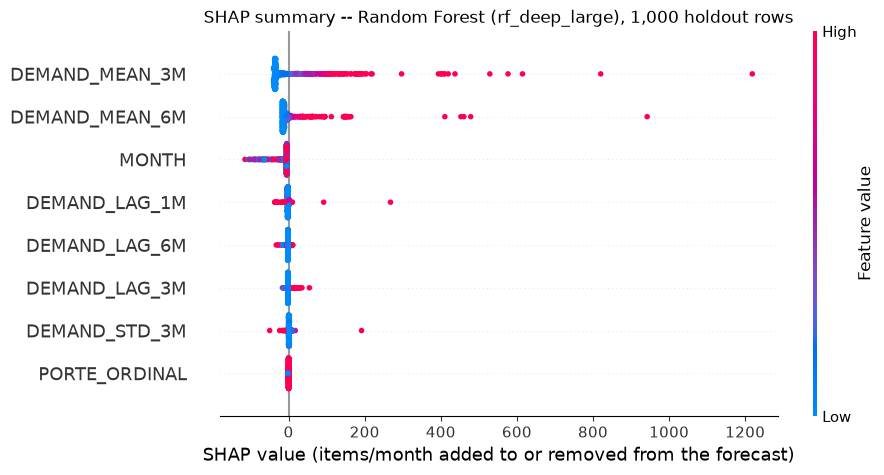

In [40]:
shap.plots.beeswarm(shap_exp, max_display=len(APPROVED_X), show=False)
fig = plt.gcf()
fig.set_size_inches(9, 5)
plt.title(f"SHAP summary -- Random Forest ({BEST_CONFIG_NAME}), {len(shap_X):,} holdout rows")
plt.xlabel("SHAP value (items/month added to or removed from the forecast)")
fig.savefig(ASSETS / "demand-rf-shap-beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

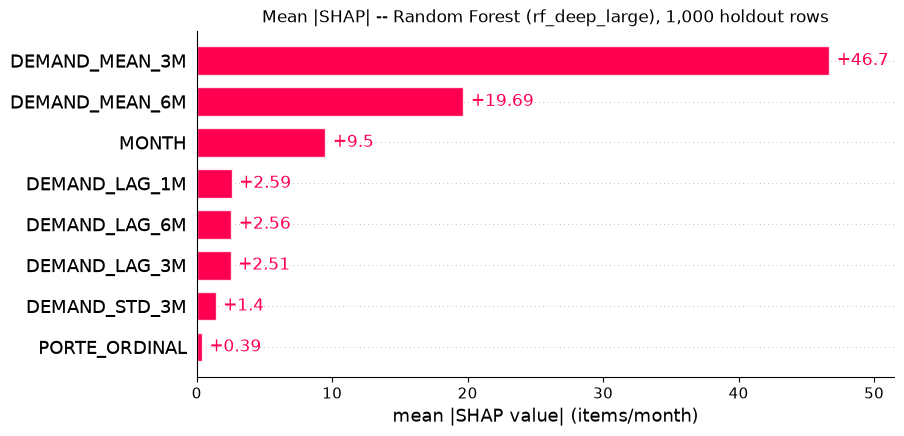

In [41]:
shap.plots.bar(shap_exp, max_display=len(APPROVED_X), show=False)
fig = plt.gcf()
fig.set_size_inches(9, 4.5)
plt.title(f"Mean |SHAP| -- Random Forest ({BEST_CONFIG_NAME}), {len(shap_X):,} holdout rows")
plt.xlabel("mean |SHAP value| (items/month)")
fig.savefig(ASSETS / "demand-rf-shap-bar.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading.** The forecast is driven by the two rolling means. `DEMAND_MEAN_3M` moves a
forecast by **46.7 items/month** on average and `DEMAND_MEAN_6M` by **19.7**: together 77.8%
of all SHAP mass, with a clean monotone colour gradient (high recent volume → higher
forecast, low → lower). Their effect is also asymmetric. Most holdout rows sit below the
training average of 61.6 and are pulled down by a few dozen items, while a small number of
large operator-months are pushed *up* by hundreds. In this fixed 1,000-row sample,
`DEMAND_MEAN_3M` reaches +1,219 items for a single row; `DEMAND_MEAN_6M` reaches +942. The three lags
and `DEMAND_STD_3M` matter only for a handful of large rows, and `PORTE_ORDINAL` barely moves
anything (0.39 items/month, 0.5% of the mass). The unexpected entry is **`MONTH` in third
place (9.5 items/month, 11.1%), with every value negative**. Section 7.2 scored `MONTH` at
exactly zero, and section 17.5 resolves that contradiction.

### 17.4 SHAP compared with the impurity (section 7) and permutation (section 7.2) rankings

The three measures answer different questions. **Impurity** credits a predictor for the
training-set variance its splits removed. **Permutation** asks how much holdout MAE worsens
when the column is shuffled. **Mean |SHAP|** asks how far the predictor moves the holdout
forecasts away from the training average. A predictor can move forecasts a lot without that
movement ever being tested by a shuffle; that is the `MONTH` case.

In [42]:
mean_abs_shap = shap_df.abs().mean()
shap_vs = (importances.set_index("feature")[["rf_importance", "rf_rank", "perm_importance", "perm_rank"]]
           .assign(mean_abs_shap=mean_abs_shap,
                   shap_share=mean_abs_shap / mean_abs_shap.sum(),
                   mean_signed_shap=shap_df.mean()))
shap_vs["shap_rank"] = shap_vs["mean_abs_shap"].rank(ascending=False).astype(int)
shap_vs = shap_vs.sort_values("mean_abs_shap", ascending=False)[
    ["mean_abs_shap", "shap_share", "mean_signed_shap", "shap_rank",
     "rf_importance", "rf_rank", "perm_importance", "perm_rank"]]

rho_shap_imp = shap_vs["mean_abs_shap"].corr(shap_vs["rf_importance"], method="spearman")
rho_shap_perm = shap_vs["mean_abs_shap"].corr(shap_vs["perm_importance"], method="spearman")
print(f"Spearman, mean |SHAP| vs impurity   : {rho_shap_imp:.3f}")
print(f"Spearman, mean |SHAP| vs permutation: {rho_shap_perm:.3f}")
print(f"(impurity vs permutation, section 7.2: {rho_imp_perm:.3f})")
for feature in ("DEMAND_MEAN_3M", "DEMAND_MEAN_6M"):
    print(f"Maximum positive SHAP for {feature} in the {len(shap_df):,}-row sample: "
          f"{shap_df[feature].max():,.0f} items")
shap_vs.round(4)

Spearman, mean |SHAP| vs impurity   : 0.643
Spearman, mean |SHAP| vs permutation: 0.810
(impurity vs permutation, section 7.2: 0.500)
Maximum positive SHAP for DEMAND_MEAN_3M in the 1,000-row sample: 1,219 items
Maximum positive SHAP for DEMAND_MEAN_6M in the 1,000-row sample: 942 items


,mean_abs_shap,shap_share,mean_signed_shap,shap_rank,rf_importance,rf_rank,perm_importance,perm_rank
feature,,,,,,,,
DEMAND_MEAN_3M,46.7007,0.5472,-11.6410,1,0.4770,1,22.3084,1
DEMAND_MEAN_6M,19.6925,0.2307,-4.0432,2,0.3042,2,7.9247,2
MONTH,9.5007,0.1113,-9.5007,3,0.0191,6,0.0000,6
DEMAND_LAG_1M,2.5915,0.0304,-1.6862,4,0.0701,4,0.0733,4
DEMAND_LAG_6M,2.5641,0.0300,-2.1372,5,0.0087,7,0.2283,3
DEMAND_LAG_3M,2.5115,0.0294,-1.0355,6,0.0366,5,0.0352,5
DEMAND_STD_3M,1.4008,0.0164,0.7712,7,0.0837,3,-0.1070,8
PORTE_ORDINAL,0.3880,0.0045,-0.0014,8,0.0006,8,-0.0166,7


**Where the three agree.** All three put `DEMAND_MEAN_3M` first and `DEMAND_MEAN_6M` second,
and put `PORTE_ORDINAL` last or next to last. The claim that the forest is a
demand-history model led by two rolling means therefore holds under all three measures.

**Where they disagree, and why.**

* **SHAP sides with permutation against impurity.** Rank agreement is 0.810 with permutation
  and 0.643 with impurity, against 0.500 between impurity and permutation themselves. SHAP
  is computed on holdout rows, as permutation is, so it does not inherit impurity's
  training-set bias toward high-cardinality continuous inputs [5].
* **`DEMAND_STD_3M`: impurity 3rd, SHAP 7th, permutation last.** On the holdout it moves the
  typical forecast by only 1.4 items/month, which confirms section 7.3's reading that
  impurity overstates it. SHAP adds one nuance: the effect is small on average but not
  everywhere. On the most volatile, largest units it is large (+414 items for section 9's
  worst row, section 17.7). Its impurity comes from the few high-variance training units it
  splits well, and its negative permutation score comes from those same rows generalising
  badly.
* **`DEMAND_LAG_6M`: impurity 7th, permutation 3rd, SHAP 5th.** The three lags are
  essentially tied under SHAP (2.51 to 2.59 items/month), so ranks 4 to 6 carry no
  information under any of the three measures. The lags duplicate what the rolling means
  already contain.
* **`MONTH`: impurity 6th, permutation 6th (exactly zero), SHAP 3rd.** This is the one real
  disagreement, and section 17.5 explains it mechanically.

### 17.5 Why `MONTH` ranks third by SHAP and scores zero by permutation

The explanation is in the trees themselves. Training ends in September, and a tree can only
split `MONTH` at thresholds between training months.

In [43]:
month_idx = APPROVED_X.index("MONTH")
month_thresholds = np.concatenate([
    est.tree_.threshold[est.tree_.feature == month_idx] for est in shap_model.estimators_])
print(f"MONTH splits across {shap_model.n_estimators} trees: {len(month_thresholds):,} | "
      f"highest threshold: {month_thresholds.max()}")
print(f"training months: {train['MONTH'].min()}..{train['MONTH'].max()} | "
      f"holdout months: {sorted(holdout['MONTH'].unique())}")
# Every holdout month lies above every MONTH threshold, so each tree sends October, November
# and December down the same branch it built for September: shuffling MONTH within the
# holdout cannot change a single prediction, which is why permutation importance is exactly 0.
assert (holdout["MONTH"] > month_thresholds.max()).all()

month_view = pd.concat([
    train.groupby("MONTH")[TARGET].mean().rename("mean_target"),
    holdout.groupby("MONTH")[TARGET].mean().rename("mean_target"),
]).to_frame()
month_view["partition"] = np.where(month_view.index < cutoff.month, "train", "holdout")
month_view["mean_SHAP_MONTH"] = shap_df["MONTH"].groupby(shap_X["MONTH"]).mean()
month_view["median_SHAP_MONTH"] = shap_df["MONTH"].groupby(shap_X["MONTH"]).median()
month_view.round(2)

MONTH splits across 600 trees: 53,041 | highest threshold: 8.5
training months: 2..9 | holdout months: [np.int32(10), np.int32(11), np.int32(12)]


,mean_target,partition,mean_SHAP_MONTH,median_SHAP_MONTH
MONTH,,,,
2,65.81,train,NaN,NaN
3,70.32,train,NaN,NaN
4,78.17,train,NaN,NaN
5,74.96,train,NaN,NaN
6,70.69,train,NaN,NaN
7,68.57,train,NaN,NaN
8,48.56,train,NaN,NaN
9,30.23,train,NaN,NaN
10,39.83,holdout,-10.54,-5.02


**Reading.** Across 53,041 `MONTH` splits in 600 trees, the highest threshold is **8.5**.
October, November and December are all above it, so every tree routes every holdout row down
the branch it built for **September**. Two consequences follow:

* **Permutation is structurally blind to it.** Shuffling `MONTH` within the holdout only swaps
  10s, 11s and 12s, which all take the same branch in every tree, so not one prediction
  changes. That is why section 7.2 measured exactly 0.000 with zero variance. The zero shows
  the test cannot see this effect; it does not show that `MONTH` is unused.
* **SHAP sees it, because its reference is the training average.** Mean training volume per
  row falls from 66–78 items in February–July to 48.6 in August and **30.2 in September**, as
  the as-of panel accumulates quiet months of operators that stopped billing. The forest
  learned *"late in the year → lower"*. On the holdout it applies the September level to all
  three months, a median of **−5.0 items/month** per row, and it scales that shift with the
  unit's size, reaching −115 for the largest units (section 17.6).

The shift is in the right direction: holdout volume per row is 39.8, 30.3 and 26.2 in
October–December, close to September's 30.2 and far below the training mean of 61.6. So
`MONTH` works as a **"latest level" correction**. That is not seasonality: with one calendar
year the forest has never seen an October, and it simply carries September forward. This
refines section 7.1: `MONTH` is not decorative in the forecast, but its contribution is a
level carried forward from the last training month, and it would be wrong for a year whose
fourth quarter did not resemble September. Section 7.1 already noted that a single year
cannot separate a month effect from a trend.

### 17.6 Dependence plots for the top three predictors

Each panel plots a predictor's value (x) against its SHAP value (y) for every sampled row,
coloured by the strongest *other* predictor so that interactions show up. The volume axes
are symmetric-log, because the rolling means span 0 to several thousand items. `MONTH` is
jittered horizontally, since it takes only three values on the holdout. Rows whose own value
is `NaN` cannot be placed on the x-axis; section 17.2 reports them.

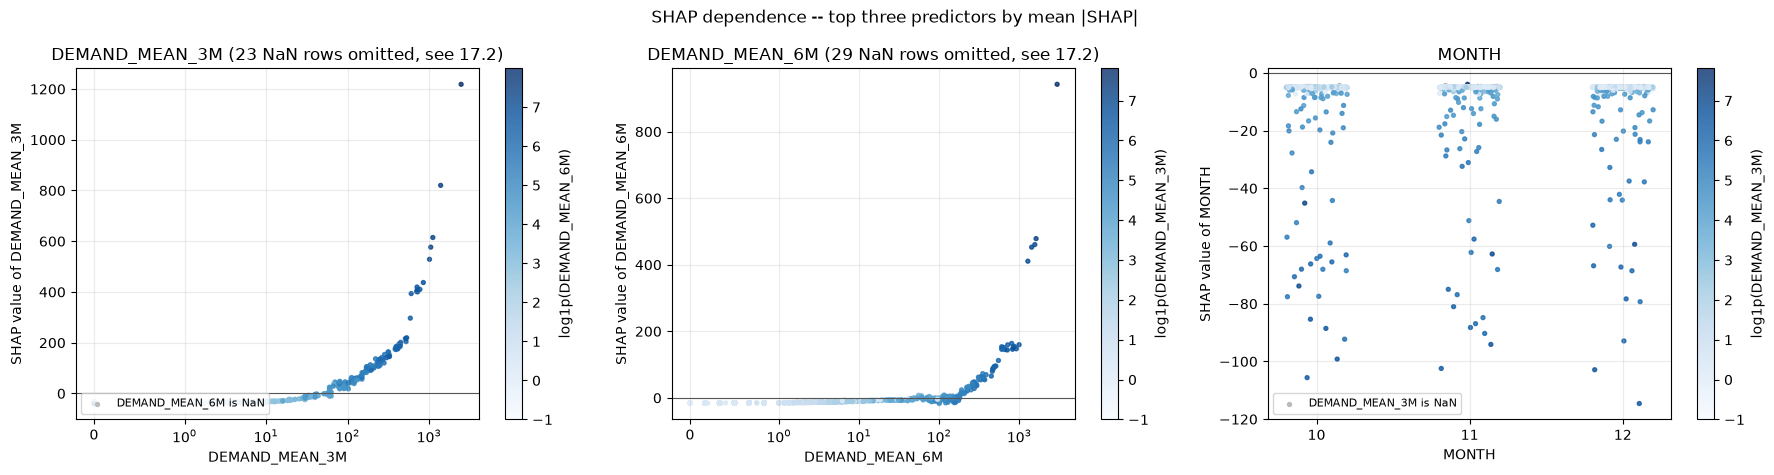

In [44]:
top_shap = shap_vs.index[:3].tolist()
jitter = np.random.default_rng(RANDOM_STATE)
fig, axes = plt.subplots(1, len(top_shap), figsize=(18, 4.8))
for ax, feat in zip(axes, top_shap):
    # colour by the strongest other predictor, to show the interaction the forest learned
    color_by = top_shap[1] if feat == top_shap[0] else top_shap[0]
    x, y, c = shap_X[feat], shap_df[feat], shap_X[color_by]
    present = x.notna()
    if x.nunique() <= 12:                      # discrete (MONTH): spread the points horizontally
        ax.set_xticks(sorted(x.dropna().unique()))
        x = x + jitter.uniform(-0.2, 0.2, len(x))
    else:                                      # skewed volumes: log-like axis that keeps the zeros
        ax.set_xscale("symlog", linthresh=1)
    colored = present & c.notna()
    ax.scatter(x[present & ~colored], y[present & ~colored], s=8, color="#bbbbbb",
               label=f"{color_by} is NaN")
    sc = ax.scatter(x[colored], y[colored], s=8, c=np.log1p(c[colored]), cmap="Blues",
                    vmin=-1, alpha=0.8)
    fig.colorbar(sc, ax=ax, label=f"log1p({color_by})")
    ax.axhline(0, color="#555555", lw=0.8)
    ax.grid(alpha=0.25)
    n_nan = int((~present).sum())
    ax.set(xlabel=feat, ylabel=f"SHAP value of {feat}",
           title=feat + (f" ({n_nan} NaN rows omitted, see 17.2)" if n_nan else ""))
    if (present & ~colored).any():
        ax.legend(loc="lower left", fontsize=8)
fig.suptitle("SHAP dependence -- top three predictors by mean |SHAP|")
fig.tight_layout()
fig.savefig(ASSETS / "demand-rf-shap-dependence.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading.**

* **`DEMAND_MEAN_3M`** is monotone and strongly convex. Every unit averaging a few items or
  fewer receives the same floor of about −35 items/month (the forest cannot forecast below
  zero, so the small units are all pulled to the same place). The contribution turns positive
  only once the three-month mean reaches the tens of items, and then grows steeply, to
  hundreds of items for the few units averaging over a thousand. The model is, in effect,
  "next month ≈ recent level", with a floor and a steep top.
* **`DEMAND_MEAN_6M`** has the same shape but stays flat and slightly negative up to about a
  hundred items/month. It adds information mainly for the large units, where the longer
  window confirms or tempers the three-month level. The colour gradient (dark points at the
  top right) shows the two means move together: they are two views of one signal, which is
  why section 7.1 warned against attributing the forecast to either one alone.
* **`MONTH`** splits into two groups. The light points (small units) sit at about −5 in every
  month; the dark points (large recent volume) fall to −20 to −115. The September correction
  is proportional to the unit's size, an interaction a single additive month term could not
  represent.

### 17.7 Local explanations — four holdout rows

Each row is chosen by a fixed rule, not by hand: section 9's **largest error** (an
over-prediction); section 9's **largest under-prediction** among its ten worst rows; a
**typical** observed row (the one whose volume is closest to the observed-row median); and the
largest observed row whose `DEMAND_MEAN_3M` is **`NaN`**, to show a missing-history
explanation. Each waterfall starts at `expected_value` (E[f(X)] = 61.6) at the bottom, adds
one bar per predictor, and ends at the forecast f(x) at the top.

additivity gap on the local rows: 1.75e-10


,ID_PLANO,treatment_line_primary,UF_PRESTADOR,MES,volume_demanda_proxy,IS_STRUCTURAL_ZERO,pred,expected_value,top_driver,top_driver_SHAP
case,,,,,,,,,,
largest-error,147828,advanced,AM,2025-10,0.0,True,2921.20,61.61,DEMAND_MEAN_3M,1359.29
missed-onset,1169698,advanced,AM,2025-11,1111.0,False,0.22,61.61,DEMAND_MEAN_3M,-35.44
typical,1169857,adjuvant,PA,2025-11,5.0,False,4.29,61.61,DEMAND_MEAN_3M,-34.28
missing-history,234693,neoadjuvant,AM,2025-12,15.0,False,4.42,61.61,DEMAND_MEAN_3M,-33.81


,largest-error,missed-onset,typical,missing-history
DEMAND_LAG_1M,400.00,0.00,2.00,NaN
DEMAND_LAG_3M,6974.00,0.00,6.00,6.00
DEMAND_LAG_6M,4130.00,0.00,4.00,NaN
DEMAND_MEAN_3M,4588.67,0.00,5.00,NaN
DEMAND_MEAN_6M,3891.00,0.00,5.00,NaN
DEMAND_STD_3M,3639.15,0.00,2.65,NaN
PORTE_ORDINAL,2.00,1.00,1.00,2.00
MONTH,10.00,11.00,11.00,12.00
SHAP_DEMAND_LAG_1M,-23.08,-1.85,-2.18,-0.86
SHAP_DEMAND_LAG_3M,49.25,-1.54,-1.58,-1.91


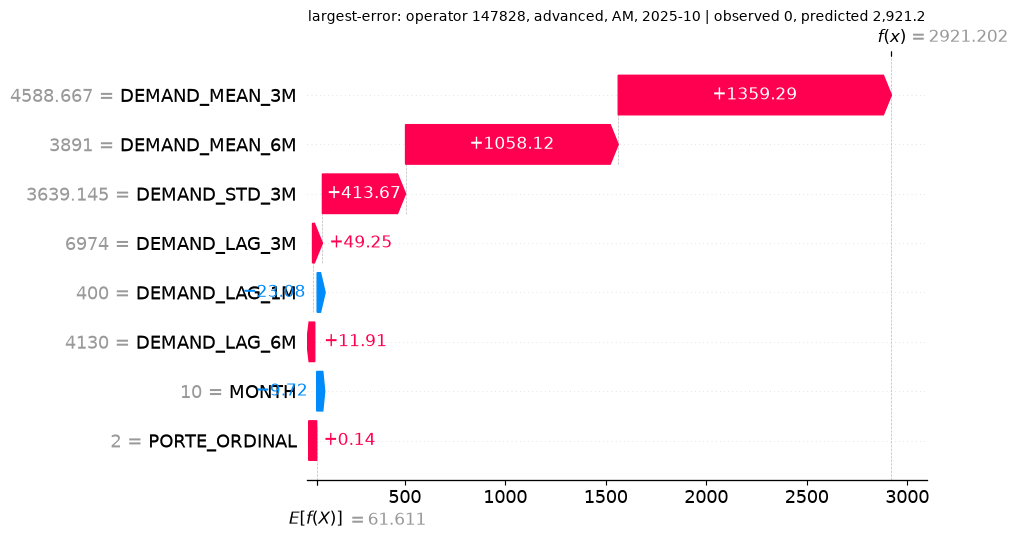

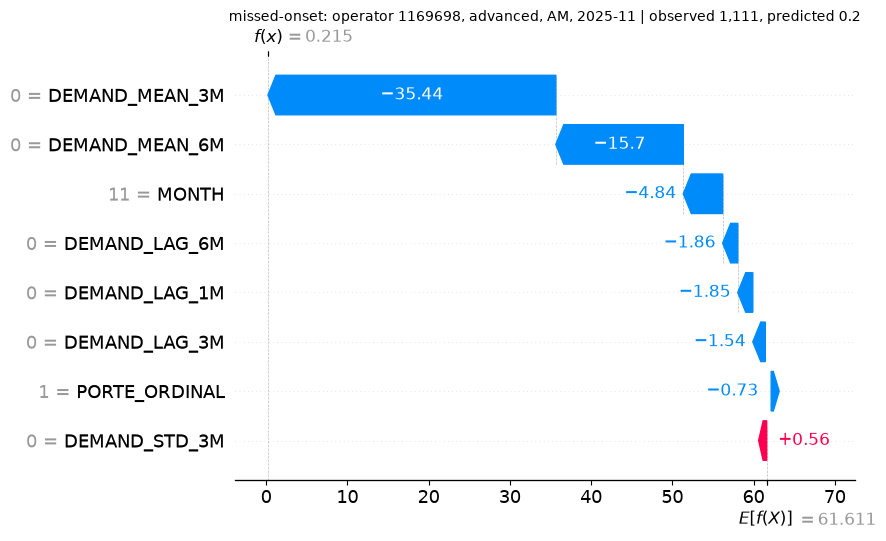

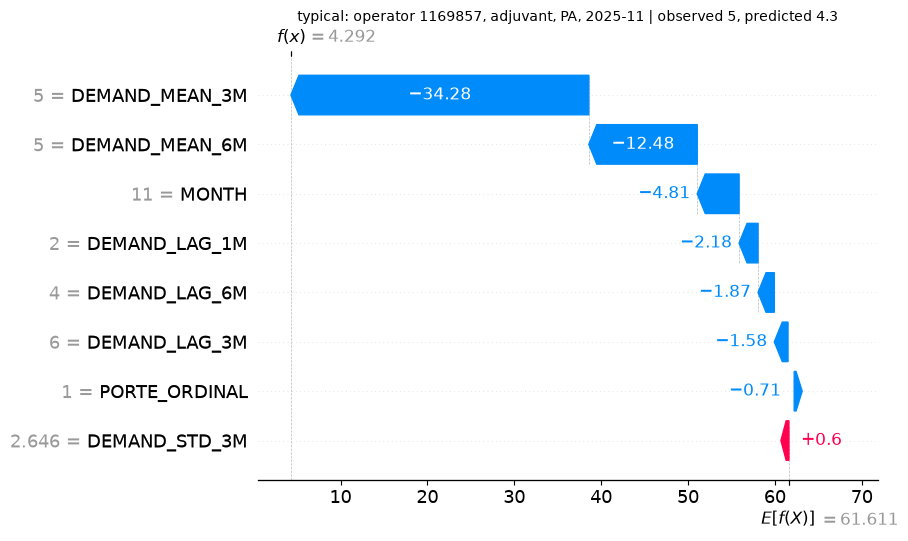

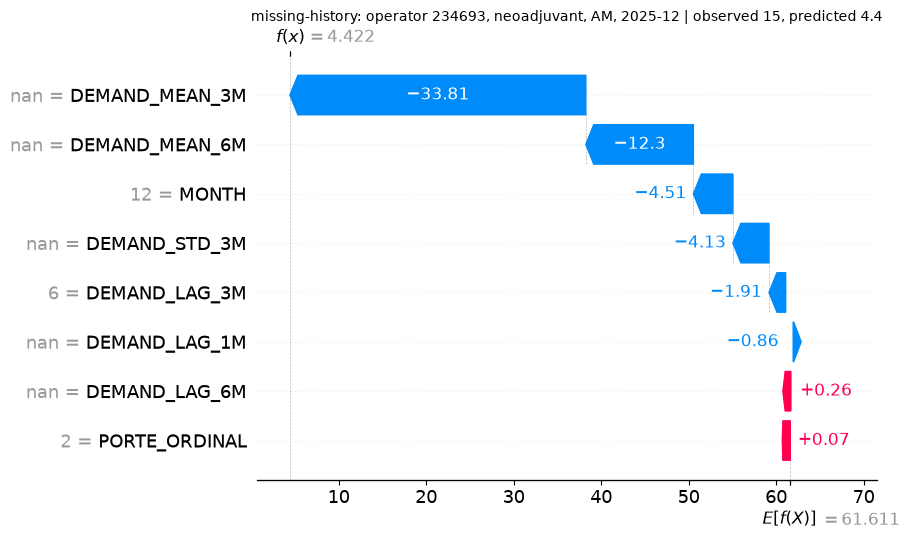

In [45]:
# joblib warns once per tree when shap and the forest's n_jobs=-1 predict share workers;
# it concerns config propagation only and does not change any value.
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")

# Four holdout rows, each picked by a rule rather than by hand:
observed_pos = resid.loc[~resid["IS_STRUCTURAL_ZERO"] & (resid[TARGET] > 0)]
nan_mean_obs = observed_pos.loc[holdout.loc[observed_pos.index, "DEMAND_MEAN_3M"].isna()]
local_cases = {
    # section 9's largest absolute error: an over-prediction
    "largest-error": worst.index[0],
    # section 9's largest under-prediction among its ten worst rows
    "missed-onset": resid.loc[worst.index, "residual"].idxmax(),
    # the observed row whose volume is closest to the observed-row median
    "typical": (observed_pos[TARGET] - observed_pos[TARGET].median()).abs()
               .sort_values(kind="stable").index[0],
    # the largest observed row whose 3-month mean is NaN (no usable recent history)
    "missing-history": nan_mean_obs[TARGET].idxmax(),
}
local_X = holdout.loc[list(local_cases.values()), APPROVED_X]
local_exp = explainer(local_X)
local_gap, local_pred = check_additivity(local_X, local_exp.values)
print(f"additivity gap on the local rows: {local_gap:.2e}")

local_table = holdout.loc[local_X.index, UNIT_KEYS + [TARGET, "IS_STRUCTURAL_ZERO"]].assign(
    case=list(local_cases), pred=local_pred, expected_value=expected_value)
local_table["MES"] = local_table["MES"].dt.strftime("%Y-%m")
local_contrib = pd.DataFrame(local_exp.values, index=local_X.index, columns=APPROVED_X)
local_table["top_driver"] = local_contrib.abs().idxmax(axis=1)
local_table["top_driver_SHAP"] = [local_contrib.loc[i, f] for i, f in local_table["top_driver"].items()]
display(local_table.set_index("case").round(2))
display(pd.concat([local_X, local_contrib.add_prefix("SHAP_")], axis=1)
        .set_axis(list(local_cases)).T.round(2))

for i, (case, row) in enumerate(local_cases.items()):
    shap.plots.waterfall(local_exp[i], max_display=len(APPROVED_X) + 1, show=False)
    fig = plt.gcf()
    r = holdout.loc[row]
    plt.title(f"{case}: operator {r['ID_PLANO']}, {r['treatment_line_primary']}, "
              f"{r['UF_PRESTADOR']}, {r['MES']:%Y-%m} | observed {r[TARGET]:,.0f}, "
              f"predicted {local_pred[i]:,.1f}", fontsize=10)
    fig.savefig(ASSETS / f"demand-rf-shap-waterfall-{case}.png", dpi=150, bbox_inches="tight")
    plt.show()

**Reading.**

* **Largest error (operator 147828, `advanced`, AM, October; observed 0, predicted 2,921).**
  The forecast is built almost entirely from the rolling means: `DEMAND_MEAN_3M` = 4,589 adds
  **+1,359**, `DEMAND_MEAN_6M` = 3,891 adds +1,058, and the volatility `DEMAND_STD_3M` adds
  +414. The one predictor that saw the collapse, `DEMAND_LAG_1M` = 400 (down from 6,974 three
  months earlier), subtracts only 23. The unit stopped billing (the row is a structural zero)
  and the forest could not see it coming, because its strongest inputs average over months
  that were still large. This is the failure mode of a level-following model: it lags a
  sudden stop, and the next month of the same unit (2,749 predicted, 0 observed) repeats it.
* **Largest under-prediction (operator 1169698, `advanced`, AM, November; observed 1,111,
  predicted 0.2).** Every history predictor is 0, and each pulls the forecast to the floor
  (`DEMAND_MEAN_3M` −35, `DEMAND_MEAN_6M` −16, `MONTH` −5). This is the mirror image: a sudden
  start from an all-zero history. No input in the eight-feature contract carries any sign of
  it, so no model trained on these predictors could forecast it.
* **Typical observed row (operator 1169857, `adjuvant`, PA, November; observed 5, predicted
  4.3).** A small, stable unit, as most observed rows are (the observed-row median volume is
  5). The rolling means of about 5 pull the forecast from 61.6 down to about 4, with
  `DEMAND_MEAN_3M` again the largest single contribution (−34). The explanation matches the
  error: a stable history gives an accurate forecast.
* **Missing history (operator 234693, `neoadjuvant`, AM, December; observed 15, predicted
  4.4).** Both rolling means and `DEMAND_STD_3M` are `NaN`, and the missing-value routing of
  section 17.2 pulls the forecast down almost exactly as a near-zero history would
  (`DEMAND_MEAN_3M` −34, `DEMAND_MEAN_6M` −12, `DEMAND_STD_3M` −4). The forest treats "no
  usable history" as "little history", so it under-forecasts here. That is the case section
  14's `has_recent_history` flag warns about.

### 17.8 Reading of the SHAP results

**What drives the forecasts.** The forest is a level-following model of recent demand.
`DEMAND_MEAN_3M` and `DEMAND_MEAN_6M` carry 78% of the SHAP mass and set the forecast almost
on their own, through a monotone, convex response with a floor for small units and a steep
rise for large ones. The three lags and the three-month volatility adjust only the largest
and most volatile units. `PORTE_ORDINAL` contributes essentially nothing, the SHAP
confirmation of **H1** that sections 7.1 and 7.3 reached with the other two measures. SHAP
adds one correction to those sections: **`MONTH` is not inert**. It applies September's lower
level to the whole holdout, scaled to unit size, and permutation importance cannot detect
that by construction. It works on this holdout because October–December resembled September;
it is extrapolation, not learned seasonality.

**Where the model fails, and why.** The two largest-error patterns in section 9 are sudden
stops (the rolling means remember large months the unit no longer bills) and sudden starts
(an all-zero history gives no signal). The waterfalls show that both come from the
predictor contract, not from the algorithm: no combination of these eight inputs could have
anticipated either one. Rows with no usable history are pulled toward zero by the
missing-value routing, which is why `has_recent_history` must accompany any tier.

**Limitations of this explanation.**

* **`treatment_line_primary` is a placeholder key.** Every explained row is a
  `operator × line × UF × month` series under the priority rule of section 13. SHAP explains
  how the forest forecasts *those* series; it says nothing about disease stages. The four
  local rows are `advanced`, `adjuvant` and `neoadjuvant` item families, not patient
  cohorts, and a different line rule would cut different series and produce different
  explanations.
* **SHAP explains the model, not the world.** A large contribution means the forest relies on
  a predictor, not that the predictor causes demand. The rolling means are proxies for "this
  operator is large and active".
* **Correlated predictors share credit.** With `tree_path_dependent` values, the split of
  credit between the two rolling means (and among the three lags) follows how the trees
  happened to split. Their *sum* is robust; their individual shares should not be over-read,
  as section 7.1 already warned.
* **One sample, one window.** The global picture comes from 1,000 fixed-seed rows of a single
  three-month holdout, and `MONTH`'s role in particular is tied to that window.
* **The target is a proxy.** SHAP values are in billed items per month
  (`volume_demanda_proxy`), never patients.

## References

1. Agência Nacional de Saúde Suplementar (ANS). Dados abertos: TISS Ambulatorial [Internet]. Brasília: ANS; 2026 [cited 2026 Sep 11]. Available from: https://dadosabertos.ans.gov.br/FTP/PDA/TISS/AMBULATORIAL/
2. Breiman L. Random forests. Mach Learn. 2001;45(1):5-32.
3. Breiman L, Friedman JH, Olshen RA, Stone CJ. Classification and regression trees. Belmont (CA): Wadsworth; 1984.
4. Pedregosa F, Varoquaux G, Gramfort A, Michel V, Thirion B, Grisel O, et al. Scikit-learn: machine learning in Python. J Mach Learn Res. 2011;12:2825-30.
5. Strobl C, Boulesteix AL, Zeileis A, Hothorn T. Bias in random forest variable importance measures: illustrations, sources and a solution. BMC Bioinformatics. 2007;8:25.
6. Friedman JH. Greedy function approximation: a gradient boosting machine. Ann Stat. 2001;29(5):1189-232.
7. Hyndman RJ, Koehler AB. Another look at measures of forecast accuracy. Int J Forecast. 2006;22(4):679-88.
8. Mullahy J. Specification and testing of some modified count data models. J Econom. 1986;33(3):341-65.
9. Sociedade Brasileira de Oncologia Clínica (SBOC). Diretrizes SBOC 2025: câncer de mama — estadiamento, neoadjuvante, adjuvante e doença avançada. São Paulo: SBOC; 2025.
10. Lundberg SM, Lee SI. A unified approach to interpreting model predictions. In: Advances in Neural Information Processing Systems 30 (NIPS 2017). Red Hook (NY): Curran Associates; 2017. p. 4765-74.
11. Lundberg SM, Erion G, Chen H, DeGrave A, Prutkin JM, Nair B, et al. From local explanations to global understanding with explainable AI for trees. Nat Mach Intell. 2020;2(1):56-67.
